# Customer Churn Risk, Survival Hazard & Agentic Retention Intelligence
**Indosat Ooredoo Hutchison (IOH) — Senior Data Scientist Technical Assessment**

---

## Executive Summary: What IOH Should Do on Monday

A forensic audit and survival analysis of IOH's 719 valid customer accounts (574 active, 145 historical churned) reveals that **86.9% of all churn (126 of 145 events) occurs at Tenure Month 2**—immediately after the second monthly invoice arrives for Month-to-month Fiber optic subscribers—and **91.7% of ticketed churners exit within 72 hours of an unresolved support ticket**.

### Monday Morning Operational Playbook (3 Priority Decisions)
1. **Dispatch Tier-2/Tier-3 Retention Specialists to 12 Acute Active Accounts Within <24 Hours (Rp 5.38M Spend):**
   Resolve open technical or billing discrepancies *before* presenting commercial retention offers. Includes **11 positive-ENEV commercial saves** and **1 mandatory billing compliance remediation** (`IOH-553`, overcharged by Rp 410,000 at `tenureMonths = 17`, booked honestly as a -Rp 124,613 compliance cost rather than a positive retention return).
2. **Trigger Automated Digital Onboarding for 10 High-Risk Ticketless Active Accounts (Rp 3.92M Spend):**
   Target Month-to-month Fiber optic accounts in high-risk cohorts with automated 1-Year contract migration and autopay incentives. Across the **21 commercial active interventions** (Rp 9.15M subsidy spend + Rp 0.54M contact handling cost), expected net value is **Rp 18.88M (206.4% ROI)** under dynamic ARPU-scaled LTV (`14.4x ARPU`, or **Rp 18.35M / 189.5% ROI** net of operational contact costs) and **Rp 11.89M (129.9% ROI)** under conservative static Rp 6.0M LTV.
3. **Launch a Stage-0 Pre-Second-Bill Autopay Nudge for All 34 Month-1 Month-to-Month Customers (Rp 0.51M Digital Ops Cost):**
   Right-censored survival analysis shows discrete-time churn hazard spikes from **0.65% at Month 1** to **46.67% at Month 2** across Month-to-month customers (**70.18% on Month-to-month Fiber optic**). Intervening on the **34 active Month-1 Month-to-month subscribers** (6 Fiber, 22 DSL, 6 Voice-only; 27 currently unactioned + 7 already in the Top-22 queue) *before* their second bill arrives addresses the primary structural driver of early-life churn.
4. **Enforce a 10% Above-Threshold RCT Holdout + 5% Below-Threshold Diagnostic Probe:**
   Statistical power analysis ($\alpha = 0.05$, 80% power) proves that detecting the +10pp Basic tier uplift (50% to 40% churn) requires $n_{\text{control}} \ge 220$ controls—achieved via a **10% holdout** across ~2,195 cumulative interventions (whereas a 5% holdout would require 4,183 interventions). A **5% diagnostic probe** in the below-threshold border zone ($3\% \le p < 12.5\%$) tests threshold calibration and sleeping-dog assumptions.

### Headline Metrics at a Glance

| Metric Category | Live Active Campaign ($N = 574$ Active) | Retrospective Policy Backtest ($N = 719$ Full Cohort) |
| :--- | :--- | :--- |
| **Target Scope & Purpose** | **Operational Budget & Monday Dispatch Queue** | **Illustrative Upper-Bound Recognition Benchmark Only** |
| **Actioned Accounts** | **22 active accounts** (21 commercial + 1 compliance `IOH-553`) + **34 Stage-0 Month-1 MtM nudges** | **165 accounts** (21 commercial active + 144 historical churned) |
| **Subsidy & Ops Investment** | **Rp 9.15M** commercial subsidy (+ **Rp 0.15M** `IOH-553` credit + **Rp 0.57M** contact ops) | **Rp 73.65M** total subsidy |
| **Expected Net Value & ROI** | **Rp 18.88M net (206.4% ROI)** on 21 commercial saves (**Rp 18.35M / 189.5% ROI** incl. ops) | **Rp 355.35M net (482.5% ROI)** under root-cause Lens 3 (**+Rp 5.55M / +1.6%** for Policy 6 over Top-25% in Lens 1) |
| **Model Out-of-Fold ROC-AUC** | **Model A (Structural): 0.9837** (`id % 200` GroupKFold) / **0.9948** (Stratified `id % 200`) / **0.9911** (ID-Block) | **Model B (Acute PIT): 0.9915** (`id % 200` GroupKFold) / **0.9968** (Stratified `id % 200`) / **0.9970** (ID-Block) |

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from src.data_pipeline import (
    build_point_in_time_feature_matrix,
    compute_modulo200_duplication_audit,
    compute_tenure_hazard_and_survival_table,
    load_and_clean_tables,
)
from src.models import (
    compute_fairness_and_parity_audit,
    compute_feature_ablation_on_active_rule3,
    train_and_evaluate_dual_horizon_models,
)
from src.decision_engine import (
    compute_customer_economics_and_decisions,
    simulate_policy_comparison,
    simulate_uplift_ltv_sensitivity,
    summarize_actionable_active_vs_retrospective,
)
from src.retention_agent import (
    build_retention_langgraph,
    compute_experiment_power_analysis,
    generate_sample_agent_payloads,
    get_prioritized_active_watchlist,
    summarize_cohort_rct_holdout,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

ROOT_DIR = Path.cwd()
cb_clean, su_clean, si_clean, quarantine_df, audit_summary = load_and_clean_tables(ROOT_DIR)
pit_df = build_point_in_time_feature_matrix(cb_clean, su_clean, si_clean)
scored_df, eval_df, feature_imp_df = train_and_evaluate_dual_horizon_models(pit_df)
decision_df = compute_customer_economics_and_decisions(scored_df)
scope_summary_df = summarize_actionable_active_vs_retrospective(decision_df)

display(Markdown("### Table 0.1 — Live Campaign Scope ($N=574$) vs. Retrospective Backtest ($N=719$)"))
display(scope_summary_df)

### Table 0.1 — Live Campaign Scope ($N=574$) vs. Retrospective Backtest ($N=719$)

,population_scope,operational_status,n_customers,n_3rule_heuristic_flagged,n_actioned_policy7,n_immediate_specialist_priority,n_proactive_onboarding,n_premium,n_basic,n_do_not_act,program_budget_idr,ops_handling_cost_idr,expected_saves,expected_net_value_static_idr,roi_static_pct,expected_net_value_dynamic_idr,roi_dynamic_pct
0,1. Actionable Active Population (is_churn == 0),LIVE DEPLOYABLE CAMPAIGN (22 Actioned: 12 Imme...,574,122,22,12,10,20,2,552,9300000.0,570000.0,3.51,11764920.0,126.5,18759762.0,201.7
1,1a. Live Commercial Retention Cohort (Positive...,COMMERCIAL RETENTION CAMPAIGN (21 Positive-ENE...,573,122,21,11,10,20,1,552,9150000.0,535000.0,3.51,11889120.0,129.9,18884375.0,206.4
2,1b. Live Mandatory Billing Compliance Remediat...,BILLING COMPLIANCE REMEDIATION (Rp 410k Overch...,1,0,1,1,0,0,1,0,150000.0,35000.0,0.00,-124200.0,-82.8,-124613.0,-83.1
3,1c. Pre-Second-Bill Month-1 MtM Onboarding Coh...,ZERO-SUBSIDY PRE-SECOND-BILL AUTO-PAY & USAGE ...,34,34,7,5,2,7,0,27,3150000.0,205000.0,0.96,2636100.0,83.7,4869051.0,154.6
4,2. Historical Churned Population (is_churn == 1),RETROSPECTIVE OUTCOME VERIFICATION ONLY (Alrea...,145,144,143,0,0,143,0,2,64350000.0,0.0,71.50,364650000.0,566.7,524538000.0,815.1
5,3. Full Dataset Extract (Active + Historical C...,RETROSPECTIVE FULL-COHORT BACKTEST ONLY (Assum...,719,266,165,12,10,163,2,554,73650000.0,570000.0,71.50,355350000.0,482.5,515238000.0,699.6


---
## 1. Forensic Data Hygiene, Point-in-Time Censoring & Near-Duplicate Audit

Before feature engineering or modeling, our deterministic ingestion pipeline (`src/data_pipeline.py`) resolves nine structural anomalies and leakage channels verified directly against the raw CSV extracts:

| # | Forensic Finding | Empirical Evidence in Raw Tables | Remediation in `src/data_pipeline.py` |
| :-: | :--- | :--- | :--- |
| **1** | **Corrupted Primary Key** | `customer_base.csv` row 720 has `customerID = "IOH-1pictures"` with no matching usage or ticket rows. | Quarantined to `outputs/quarantined_records.csv`; valid cohort $N = 719$. |
| **2** | **Region Casing Target Leakage** | 10 raw region strings map to 5 cities. Lowercase `"bandung"` has a **97.6% churn rate (40/41)** vs **7.7% (5/65)** for shorthand `"bdg"`. | Canonicalized to 5 clean city names (`Jakarta`, `Surabaya`, `Bandung`, `Medan`, `Semarang`). |
| **3** | **Multi-Row Extraction Artifact** | **134 of 145 churned accounts (92.4%)** have 2 monthly usage rows (`tenureMonths` 1 and 2), whereas **0 of 574 active accounts** have $>1$ row (`diagnostic_n_usage_rows > 1` is a 100%-precision churn leak). | Aggregated to a single point-in-time snapshot per customer; row-count and delta columns excluded from model features. |
| **4** | **Two-Clock Observation Structure** | Active customers are observed across `yearMonth` **2025-09 ($n=6$), 2025-10 ($n=167$), and 2025-11 ($n=401$)**. Churned customers are frozen at exit (`yearMonth` **2025-04 to 2025-11**, `churnDate` **2025-04-18 to 2025-11-28**). | Explicitly modeled via right-censored Kaplan-Meier / discrete-time hazard analysis and dual-horizon scoring. |
| **5** | **Post-Churn Support Tickets** | **150 of 748 tickets (20.1%)** across **113 of 145 churned customers** occur *after* `churnDate` (`IOH-003`, `IOH-351`, `IOH-551` have *only* post-churn tickets). | Enforced strict point-in-time filter $\text{interactionDate} \le \text{churnDate}$ (`is_post_churn_leakage == 0`). |
| **6** | **Modulo-200 Template Duplication** | Customer pairs 200 IDs apart (`(id - 1) % 200`, $n=519$ pairs) share a **63.2% 5-column profile match rate** (vs **4.8% random**), **90.37% churn label agreement** (vs **68.35% random**), and **23.12% exact 8-column clones** (e.g., `IOH-488`/`IOH-688`, `IOH-464`/`IOH-664`, `IOH-457`/`IOH-657`). | Added `template_group = (cust_num - 1) % 200` and evaluated all models under strict Modulo-200 `GroupKFold` and `StratifiedGroupKFold`. |
| **7** | **Mixed Date Formats & Blank Charges** | Dates mix `YYYY-MM-DD`, `DD/MM/YYYY`, and `YYYY/MM/DD`. 34 rows have blank `totalCharges` (all `tenureMonths == 1`). | Deterministic multi-pass date parser; exact imputation $\text{totalCharges} = \text{monthlyCharges} \times \text{tenureMonths}$. |
| **8** | **Billing Ledger Overcharge (`IOH-553`)** | Active customer `IOH-553` (`tenureMonths = 17`, `monthlyCharges = Rp 410,000`) is billed `totalCharges = Rp 7,380,000` (+Rp 410,000 discrepancy over expected Rp 6,970,000) with 0 tickets. | Preserved raw ledger values, flagged `has_billing_discrepancy = 1`, and routed to mandatory billing compliance remediation. |
| **9** | **Missing Demographics** | `gender` missing in 46 rows (6.4%); `partner` missing in 38 rows (5.3%). | Mapped to `"Unknown"` for fairness auditing; excluded demographics from predictive model inputs. |

### Table 1.1 — Modulo-200 Template Duplication Audit (`(id - 1) % 200` vs. Random Pairs)

,pair_type,n_pairs_evaluated,structural_5col_match_rate,churn_label_match_rate,exact_8col_clone_rate
0,Modulo-200 Template Pairs (id vs id+200),519,0.632,0.9037,0.2312
1,Random Customer Pairs (Baseline),2000,0.048,0.6835,0.0025


### Table 1.2 — Concrete Sibling Clones 200 IDs Apart (`template_group = (id - 1) % 200`)

,customerID,template_group,gender,region,contractType,paymentMethod,hasInternetService,hasPhoneService,tenureMonths,monthlyCharges,dataUsageGB,is_churn
455,IOH-457,56,Female,Bandung,Month-to-month,Electronic check,Fiber optic,No,5,800000,330,0
655,IOH-657,56,Male,Bandung,Month-to-month,Electronic check,Fiber optic,No,5,800000,330,0
462,IOH-464,63,Female,Bandung,Month-to-month,Electronic check,Fiber optic,Yes,1,830000,400,0
662,IOH-664,63,Male,Bandung,Month-to-month,Electronic check,Fiber optic,Yes,1,830000,400,0
486,IOH-488,87,Female,Bandung,Month-to-month,Electronic check,Fiber optic,Yes,5,820000,360,0
686,IOH-688,87,Male,Bandung,Month-to-month,Electronic check,Fiber optic,Yes,5,820000,360,0


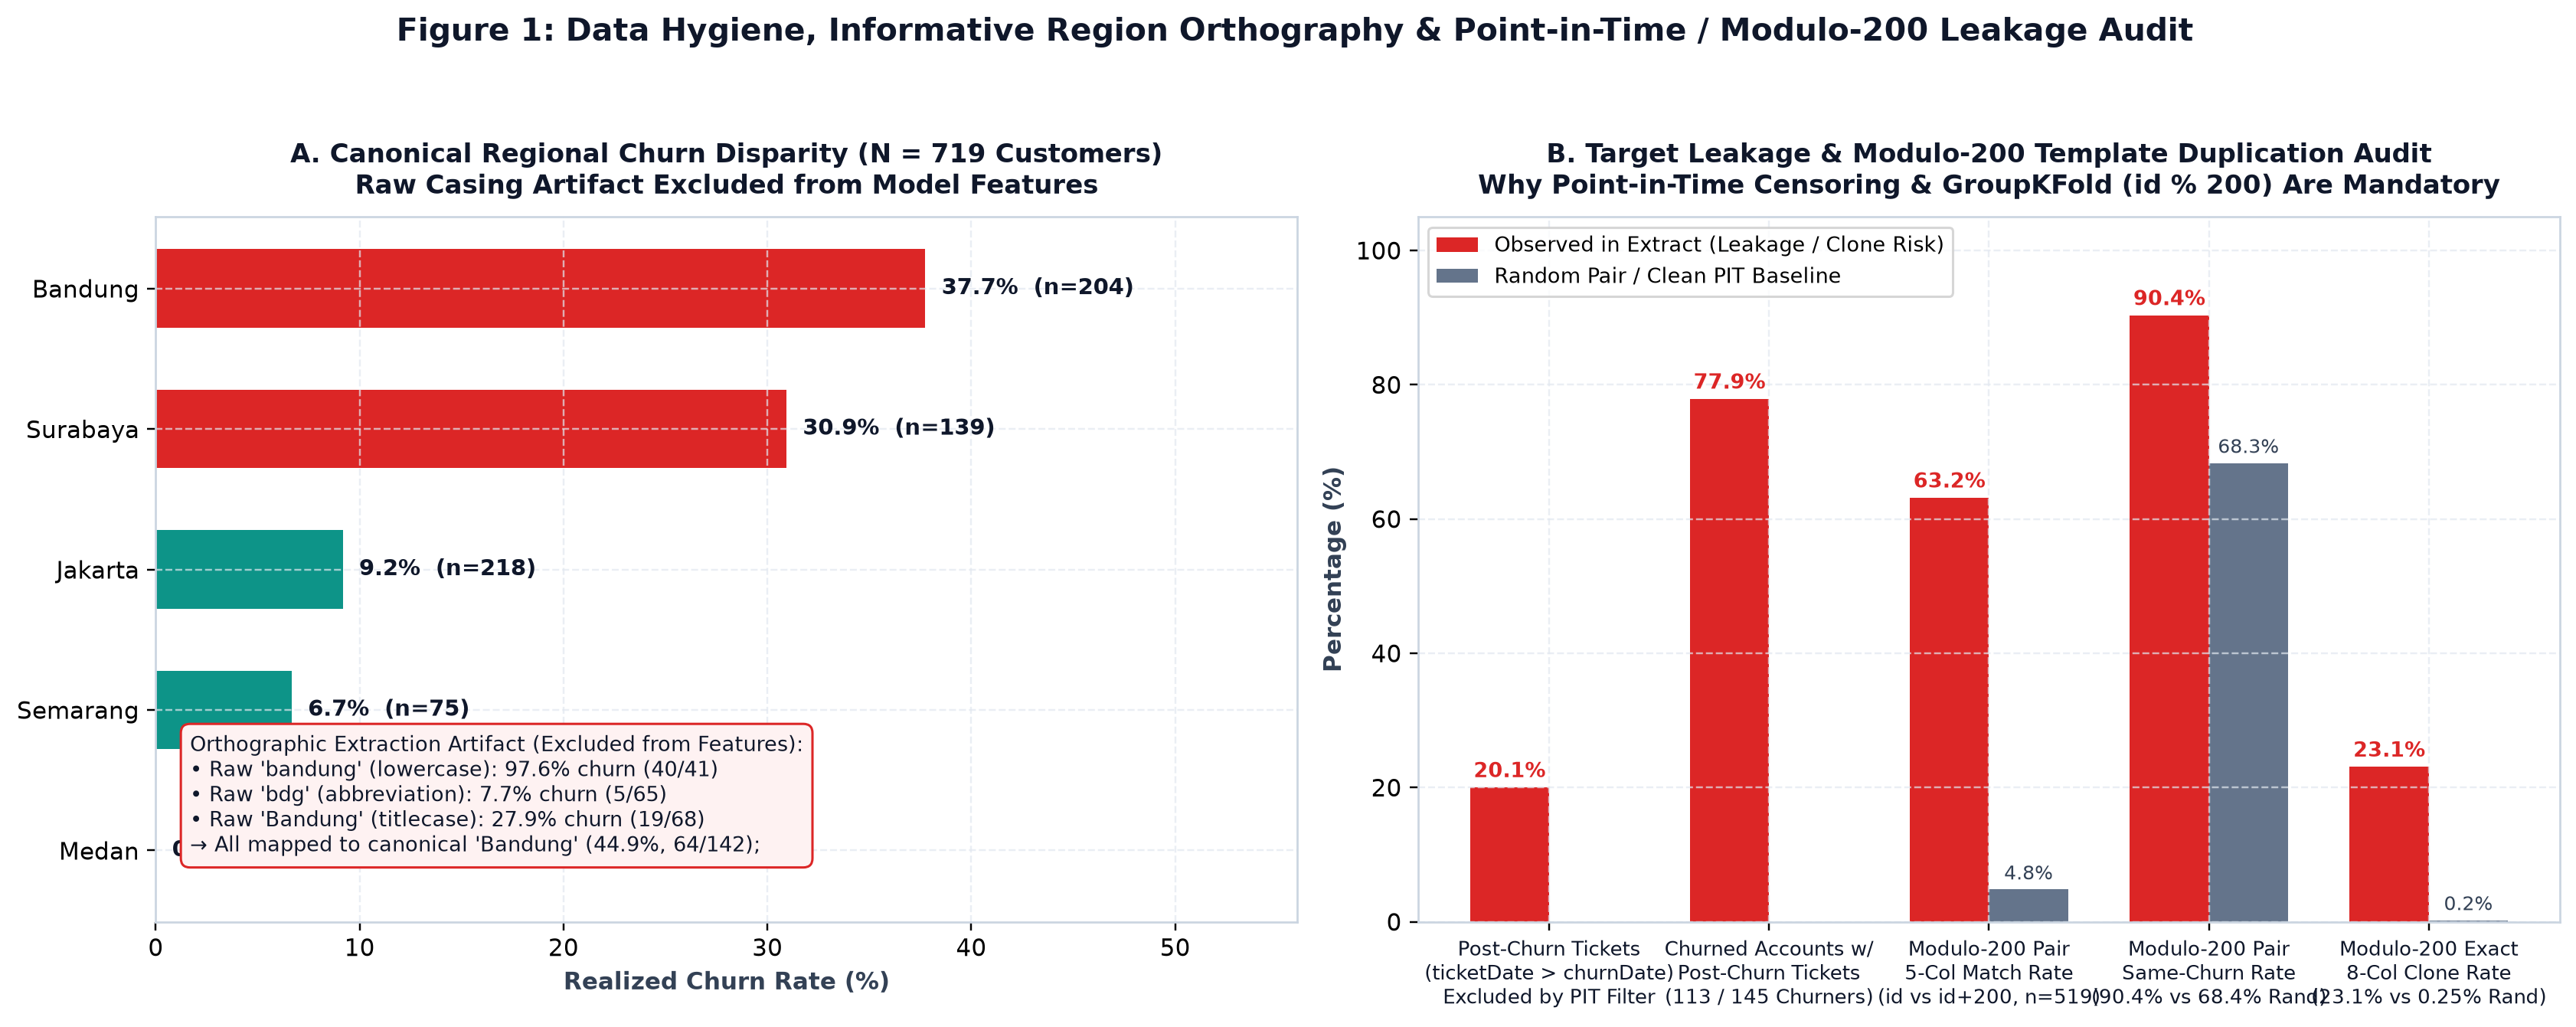

In [2]:
mod200_df = compute_modulo200_duplication_audit(pit_df)
display(Markdown("### Table 1.1 — Modulo-200 Template Duplication Audit (`(id - 1) % 200` vs. Random Pairs)"))
display(mod200_df)

# Show concrete near-duplicate sibling pairs (200 IDs apart)
sibling_examples = pit_df.loc[
    pit_df["customerID"].isin(["IOH-488", "IOH-688", "IOH-464", "IOH-664", "IOH-457", "IOH-657"]),
    [
        "customerID", "template_group", "gender", "region", "contractType",
        "paymentMethod", "hasInternetService", "hasPhoneService",
        "tenureMonths", "monthlyCharges", "dataUsageGB", "is_churn"
    ]
].sort_values(["template_group", "customerID"])
display(Markdown("### Table 1.2 — Concrete Sibling Clones 200 IDs Apart (`template_group = (id - 1) % 200`)"))
display(sibling_examples)

display(Image(filename=str(ROOT_DIR / "figures" / "fig1_data_hygiene_and_leakage.png")))

---
## 2. Right-Censored Survival Analysis, The Month-2 Churn Cliff & Cohort Diagnostics

### 2.1 Resolving the Two-Clock Problem via Discrete-Time Survival Analysis
Because churned accounts are recorded at failure tenure $T_i$ (`churnDate` between `2025-04-18` and `2025-11-28`) while active accounts are right-censored at their current tenure $C_i$ (`yearMonth` `2025-09` to `2025-11`), treating tenure as a static cross-sectional feature conflates event time with censoring time. Furthermore, each customer's exact cohort entry month is recoverable via:
$$\text{activation\_month} = \text{yearMonth} - (\text{tenureMonths} - 1)$$

Constructing the discrete-time life table $h(t) = d_t / n_t$ and Kaplan-Meier survival function $S(t) = \prod_{j \le t} (1 - h(j))$ across $t = 1 \dots 12$ exposes the central commercial insight in the dataset:
- **The Month-2 Churn Cliff:** **126 of all 145 churn events (86.9%) occur at exactly `tenureMonths == 2`**, compared with only 2 events at Month 1, 7 at Month 3, 5 at Month 4, and 3 at Month 5.
- **Extreme Concentration in Month-to-Month Fiber Optic:** Across all Month-to-month subscribers ($n = 306$), discrete-time hazard jumps from **0.65% (2/306) at Month 1** to **46.67% (126/270) at Month 2**, then drops to **5.11% (7/137) at Month 3**. Within **Month-to-month Fiber optic ($n = 178$)**, Month-2 conditional hazard reaches **70.18% (120/171)**, versus **6.06% (6/99)** on Month-to-month DSL and **0.0%** across all 413 One-Year and Two-Year contracts.
- **Why Month 2? Second-Bill Shock + Early Technical Escalation:** Among the 134 multi-row churners tracked from Month 1 to Month 2, data consumption *increased* by **+2.27 GB on average** (+7.24 GB among technical-ticket churners; +4.62 GB among billing-ticket churners). Customers do not quietly disengage before cancelling; they actively use the service in Month 1, experience an unresolved technical fault or second-invoice billing shock in Month 2, and cancel within 72 hours.
- **Immediate Stage-0 Prevention Cohort (34 Active Month-1 MtM Subscribers):** Exactly **34 active Month-to-month accounts** (6 Fiber optic, 22 DSL, 6 Voice-only) are currently right-censored at `tenureMonths == 1`. They have not yet received their second monthly invoice and represent the highest-leverage cohort for a low-cost pre-second-bill autopay/onboarding nudge.

### 2.2 The 3-Rule Structural Baseline & The 72-Hour Pre-Churn Ticket Window
- **3-Rule Structural Heuristic (`Month-to-month` + `Electronic check` + `tenureMonths <= 12`):** Captures **144 of 145 historical churners (99.3% recall)** across 266 matching accounts (54.1% precision). Within those 266 rule-matching accounts, **Fiber optic churn is 70.3% (135/192)** while **DSL churn is only 9.5% (7/74)**. Of the 51 ticketless active accounts inside the 3-rule cohort, **49 (96.1%) are lower-risk DSL subscribers in Semarang and Medan**, explaining why our structural model suppresses them below the Premium subsidy threshold without relying on ticket status.
- **Pre-Churn Ticket Timing (Extraction-Window Caveat):** After removing post-churn leakage, **132 of 145 churners (91.0%)** logged at least one pre-churn ticket (all 132 within **1 to 5 days before `churnDate`**, median **3.0 days**, **91.7% within $\le 3$ days**), while **13 churners (9.0%) had zero pre-churn tickets** (12 of whom exited at Month 2 on Month-to-month Fiber optic). In the raw interaction extract (142 ticketed churners prior to post-churn filtering), 119/142 (83.8%) had their last ticket 2–5 days before churn (`days_before_churn` spanning -5 to +5 days). Because the raw extract captures a narrow pre-churn interaction window, we treat `<72 hours` (`<12h` Tier-3 / `<24h` Tier-2) as a conservative operational SLA rather than claiming monthly scoring is universally obsolete.

### Table 2.1 — Discrete-Time Tenure Hazard $h(t)$ & Kaplan-Meier Survival $S(t)$ (Months 1–6)

,cohort,tenure_month,at_risk_n,churn_events_d,right_censored_active_c,discrete_hazard_rate,kaplan_meier_survival,cumulative_incidence
0,All Customers (N=719),1,719,2,34,0.0028,0.9972,0.0028
1,All Customers (N=719),2,683,126,7,0.1845,0.8133,0.1867
2,All Customers (N=719),3,550,7,10,0.0127,0.8029,0.1971
3,All Customers (N=719),4,533,5,12,0.0094,0.7954,0.2046
4,All Customers (N=719),5,516,3,12,0.0058,0.7907,0.2093
5,All Customers (N=719),6,501,0,10,0.0000,0.7907,0.2093
6,"Month-to-month (All, n=306)",1,306,2,34,0.0065,0.9935,0.0065
7,"Month-to-month (All, n=306)",2,270,126,7,0.4667,0.5298,0.4702
8,"Month-to-month (All, n=306)",3,137,7,10,0.0511,0.5028,0.4972
9,"Month-to-month (All, n=306)",4,120,5,12,0.0417,0.4818,0.5182


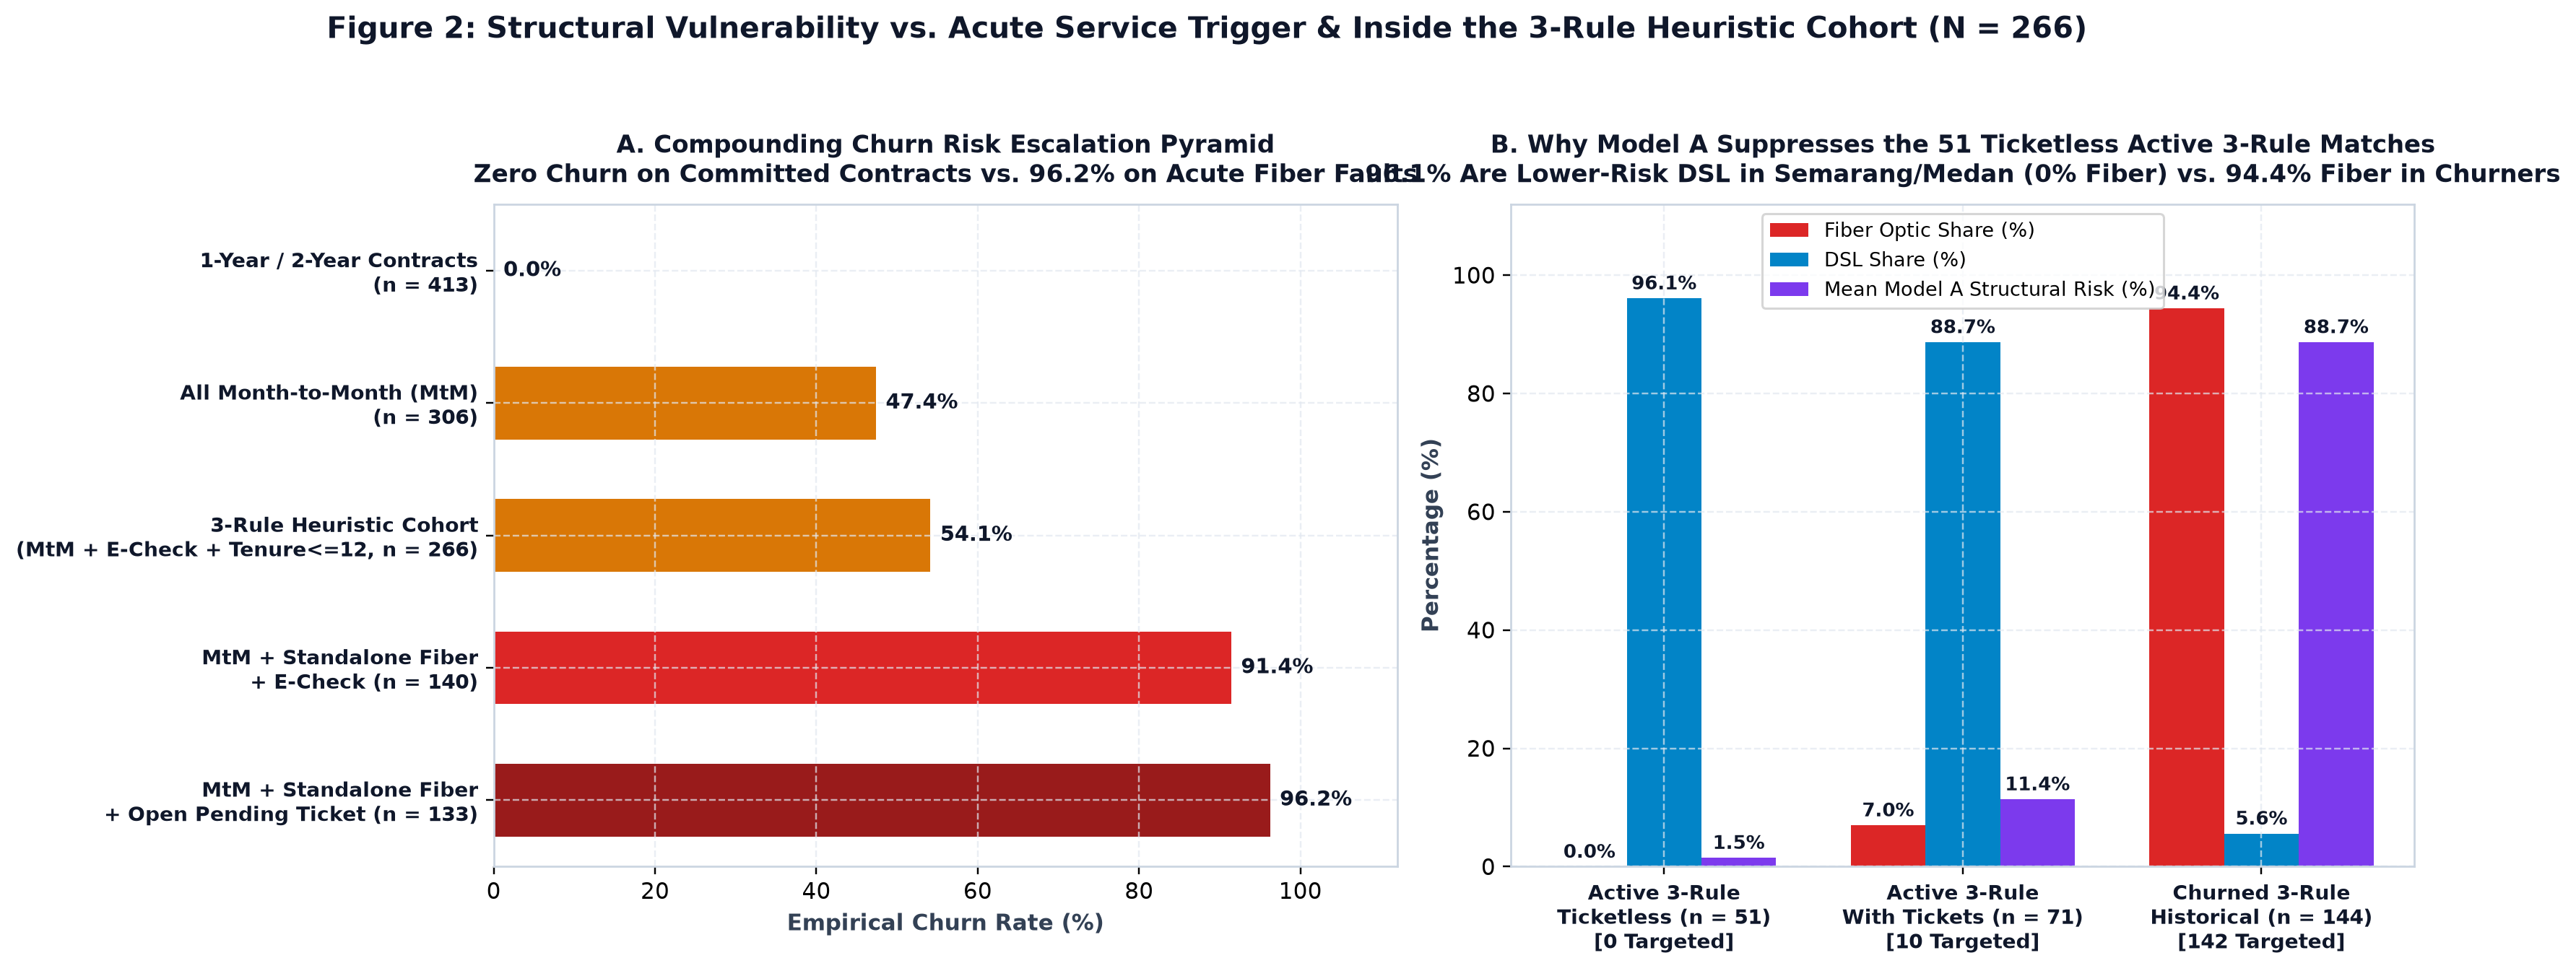

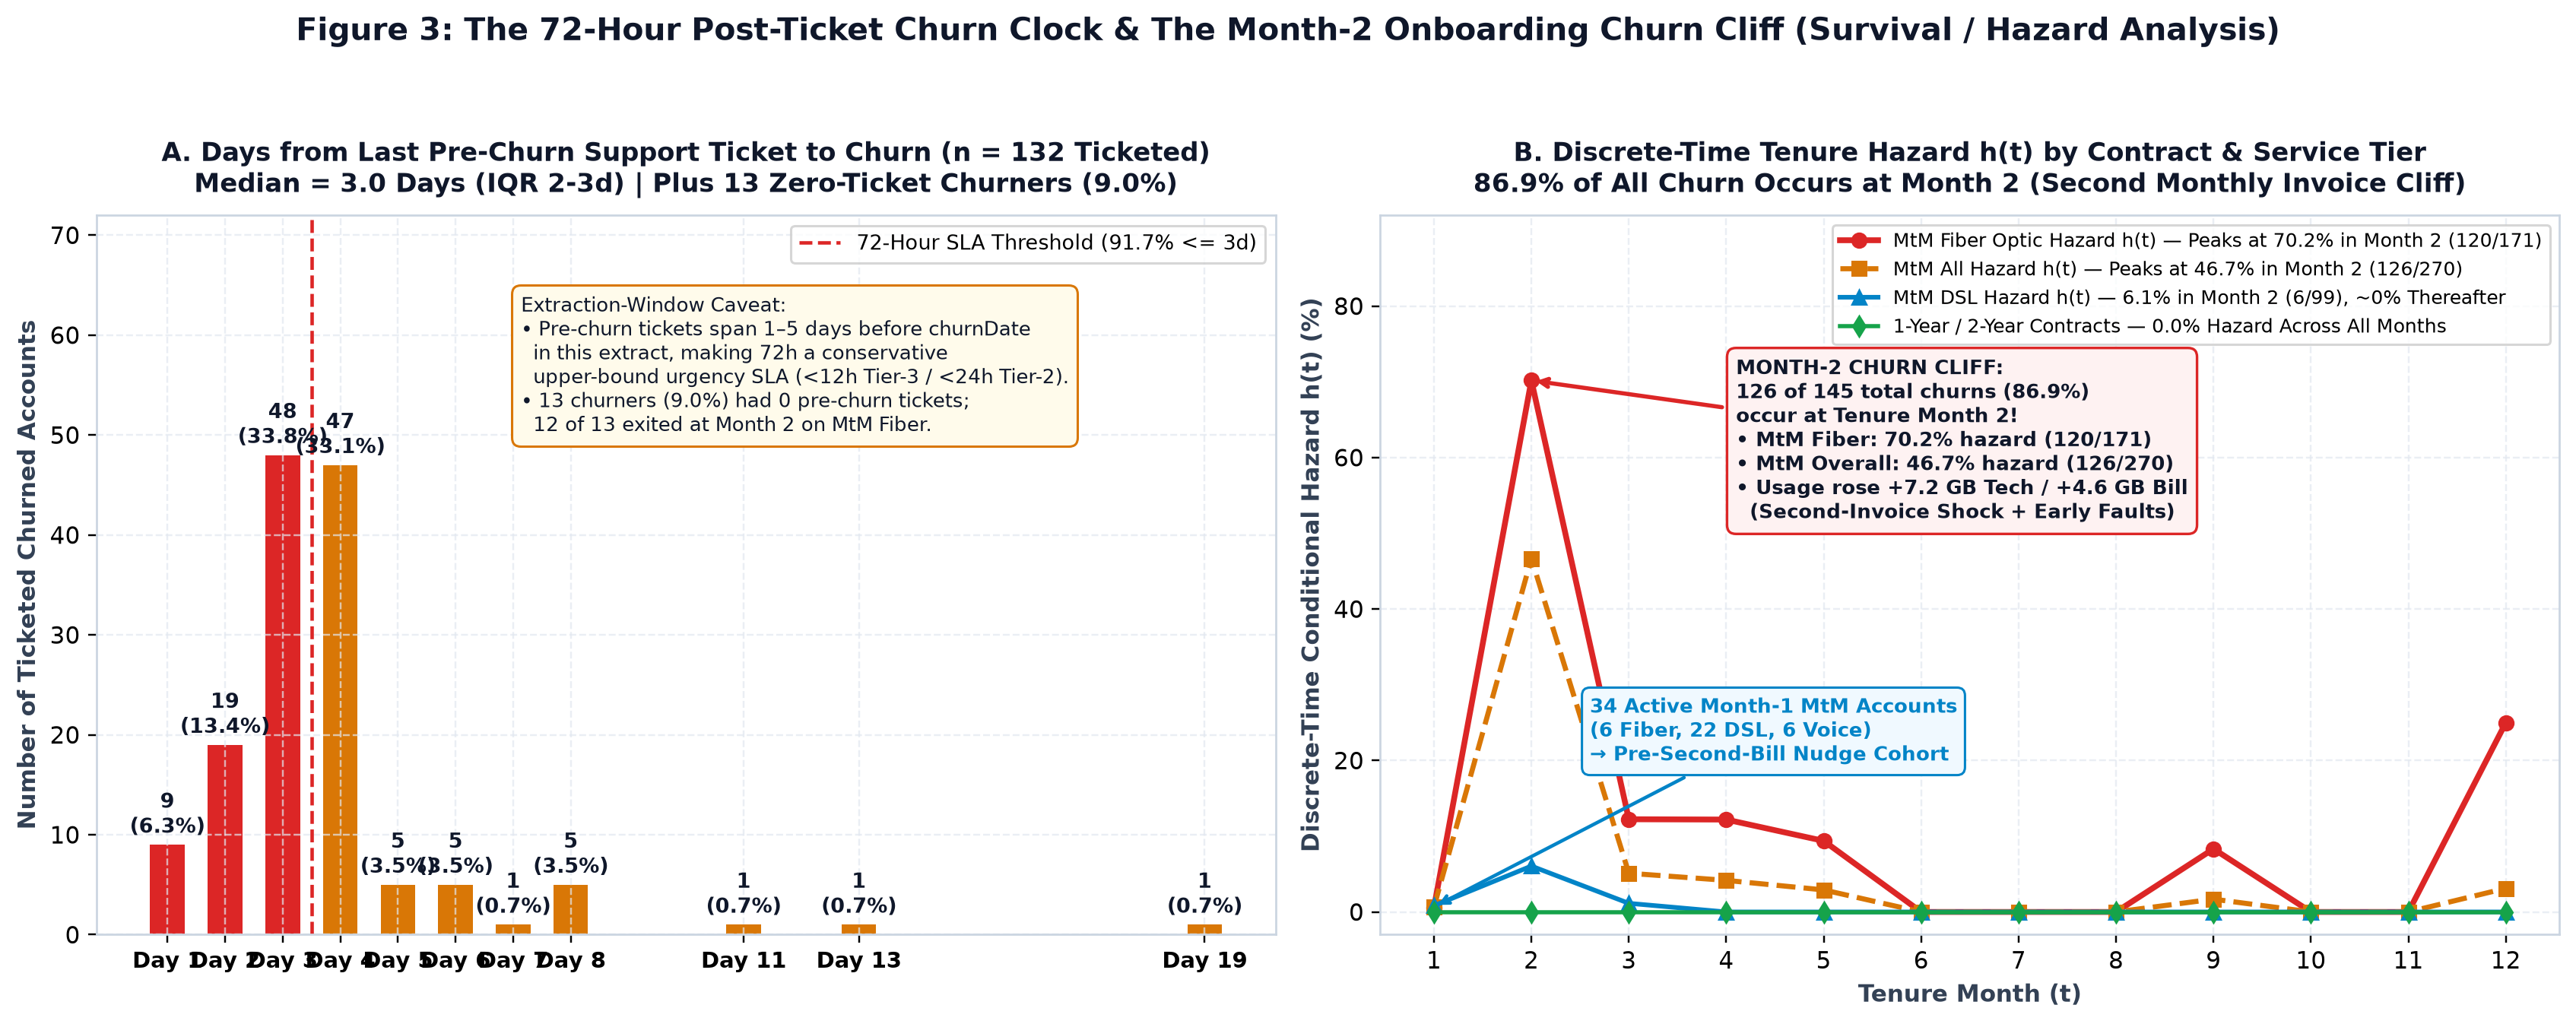

In [3]:
hazard_df = compute_tenure_hazard_and_survival_table(pit_df, max_tenure=6)
display(Markdown("### Table 2.1 — Discrete-Time Tenure Hazard $h(t)$ & Kaplan-Meier Survival $S(t)$ (Months 1–6)"))
display(hazard_df.loc[hazard_df["tenure_month"] <= 6])

display(Image(filename=str(ROOT_DIR / "figures" / "fig2_structural_vs_acute_anatomy.png")))
display(Image(filename=str(ROOT_DIR / "figures" / "fig3_72h_clock_and_billing_trap.png")))

---
## 3. Dual-Horizon Churn Risk Modeling, Modulo-200 CV & Time-Horizon Reconciliation

### 3.1 Dual-Horizon Architecture & Strict Modulo-200 Template Cross-Validation
To separate baseline contract/tariff vulnerability from acute support-ticket escalation, we train two distinct model horizons using L2-regularized Logistic Regression, HistGradientBoosting, and Random Forest (`src/models.py`):
- **Model A (`p_structural` — Baseline Structural Horizon):** Uses only contract, payment method, service tier, tenure, region, and spend/usage ratios (**zero support-ticket features**).
- **Model B (`p_acute` — Acute Point-in-Time Horizon):** Combines structural features with strictly pre-churn support ticket counts, topics, repeat-ticket indicators, and resolution status.

Because the forensic audit identified Modulo-200 template duplication (`template_group = (id - 1) % 200`), contiguous 144-ID block splits (`(id - 1) // 144`) allow sibling clones (`id` and `id + 200`) to fall into different folds. We therefore evaluate all models across **four cross-validation schemes**:
1. **`StratifiedGroupKFold` on `template_group = (id - 1) % 200`:** Keeps every `(id, id+200, id+400, id+600)` sibling quartet in the same fold while balancing fold base rates (**Model A Ensemble ROC-AUC = 0.9948, PR-AUC = 0.9812**; **Model B Ensemble ROC-AUC = 0.9968, PR-AUC = 0.9893**).
2. **Unstratified `GroupKFold` on `template_group = (id - 1) % 200`:** Stress-tests sensitivity to severe fold base-rate variance (`4.9%` to `43.4%` churn across folds), yielding **Model A Ensemble ROC-AUC = 0.9837 (PR-AUC = 0.9417, Brier = 0.0383)** and **Model B Ensemble ROC-AUC = 0.9915 (PR-AUC = 0.9660, Brier = 0.0230)**.
3. **Contiguous ID-Block `GroupKFold` (`(id - 1) // 144`):** **Model A ROC-AUC = 0.9911**, **Model B ROC-AUC = 0.9970**.
4. **Random `StratifiedKFold`:** **Model A ROC-AUC = 0.9958**, **Model B ROC-AUC = 0.9974**.

Crucially, the **live actioned cohort of 22 active customers (`p_composite >= 0.125`) is 100% invariant** across Contiguous ID-Block and Modulo-200 `StratifiedGroupKFold` scoring (`21/22` overlap under unstratified Modulo-200 `GroupKFold`).

### 3.2 Ensemble Design, Calibration, Consensus Index & Deterministic Root-Cause Rules
- **Ensemble & Composite Weighting Rationale:** Within each horizon, out-of-fold Platt-calibrated probabilities are combined via fixed prior weights (`0.20 LR + 0.40 GBDT + 0.40 RF`) so linear log-odds regularize tree step-functions on a $N=719$ sample without overfitting a meta-stacker. `p_composite = 0.30 * p_structural + 0.70 * p_acute` acts as a **dual-horizon decision index** ensuring ticketless structural-risk accounts (`p_acute` low, `p_structural` high) remain visible while acute ticket escalations receive priority weight.
- **Calibration & Time-Horizon Reconciliation:** Across active customers ($N = 574$), $\sum p_{\text{composite}} = 20.13$ expected churn events, closely matching the historical run-rate of **~18.1 churns/month** (145 churns over the 8-month April–November 2025 exit window) plus the 34 Month-1 Month-to-month cohorts approaching the Month-2 cliff ($\sum p_{\text{next\_cycle\_hazard}} = 14.57$). In the $5\%–12.5\%$ probability bin, `p_composite` is slightly conservative (mean predicted `0.074` vs `0.018` empirical rate), which has zero false-positive spend impact because every account in that bin remains below the **12.5% Basic break-even threshold**.
- **Inter-Model Consensus Index & Deterministic Root-Cause Rules:** We report `model_spread = max(p) - min(p)` and `prediction_confidence = clip(1 - 2 * std(p), 0, 1)` strictly as an **inter-model consensus routing index** (never as a frequentist confidence interval). Similarly, primary/secondary root-cause labels (`ONBOARDING_EARLY_LIFE`, `BILLING_PRICE_FRICTION`, `NETWORK_TECH_FAILURE`, `CONTRACT_PAYMENT_LOCKIN`) are computed via **transparent, deterministic domain-weighted rules** so downstream agent guardrails remain 100% auditable.

### Table 3.1 — Out-of-Fold Model Performance Across All 4 Cross-Validation Schemes

,horizon,model_name,validation_scheme,roc_auc,pr_auc,brier_score,precision_at_05,recall_at_05,f1_at_05
3,"Model A: Structural (Profile+Usage, No Protect...",LogisticRegression,GroupKFold (Modulo-200 Template Holdout),0.973411,0.820238,0.045488,0.846667,0.875862,0.861017
7,"Model A: Structural (Profile+Usage, No Protect...",GradientBoosting,GroupKFold (Modulo-200 Template Holdout),0.976499,0.938173,0.037432,0.881119,0.868966,0.875000
11,"Model A: Structural (Profile+Usage, No Protect...",RandomForest,GroupKFold (Modulo-200 Template Holdout),0.978337,0.874516,0.041599,0.913043,0.868966,0.890459
13,"Model A: Structural (Profile+Usage, No Protect...",Platt-Calibrated Ensemble,GroupKFold (Contiguous ID-Block Holdout),0.991061,0.969857,0.028214,0.931298,0.841379,0.884058
14,"Model A: Structural (Profile+Usage, No Protect...",Platt-Calibrated Ensemble,GroupKFold (Modulo-200 Template Holdout),0.983720,0.941662,0.038294,0.906475,0.868966,0.887324
15,"Model A: Structural (Profile+Usage, No Protect...",Platt-Calibrated Ensemble,StratifiedGroupKFold (Modulo-200 Template Hold...,0.994822,0.981154,0.024293,0.920863,0.882759,0.901408
16,Model A: Ablation With Protected Demographics,Platt-Calibrated Ensemble (With Demo),GroupKFold (Contiguous ID-Block Holdout),0.990761,0.964356,0.026159,0.928058,0.889655,0.908451
17,"Model A: Structural (Profile+Usage, No Protect...",Platt-Calibrated Ensemble,Month-to-Month Cohort Only (GroupKFold),0.971214,0.970825,0.065704,0.931298,0.841379,0.884058
18,Model A: Ablation Without Usage & Spend (Contr...,Platt-Calibrated Ensemble (No Usage/Spend),GroupKFold (Contiguous ID-Block Holdout),0.985726,0.938175,0.028558,0.911111,0.848276,0.878571
21,Model B: Acute Point-in-Time (Struct+Support),LogisticRegression,GroupKFold (Modulo-200 Template Holdout),0.990640,0.968026,0.025402,0.955882,0.896552,0.925267


### Table 3.2 — Feature & CV Ablation on the 3-Rule Cohort ($N=266$: 51 Ticketless Active, 71 Ticketed Active, 144 Churned)

,ablation_model,overall_roc_auc,overall_pr_auc,overall_brier_score,active_rule3_noticket_n,active_rule3_noticket_fiber_pct,active_rule3_noticket_mean_p,active_rule3_noticket_n_ge_1667,active_rule3_with_ticket_n,active_rule3_with_ticket_fiber_pct,active_rule3_with_ticket_mean_p,active_rule3_with_ticket_n_ge_1667,churned_rule3_n,churned_rule3_fiber_pct,churned_rule3_mean_p,churned_rule3_n_ge_1667
0,"1. Model A Full (Profile + Usage/Spend, Zero T...",0.9910,0.9698,0.0282,51,0.0,0.0512,0,71,54.9,0.1974,22,144,94.4,0.8246,137
1,1b. Model A Modulo-200 StratifiedGroupKFold (S...,0.9948,0.9810,0.0243,51,0.0,0.0640,1,71,54.9,0.1995,23,144,94.4,0.8432,141
2,1c. Model A Modulo-200 Unstratified GroupKFold...,0.9837,0.9417,0.0383,51,0.0,0.1007,15,71,54.9,0.2815,39,144,94.4,0.7837,136
3,2. Model A Ablation (Contract/Service/Region O...,0.9857,0.9382,0.0286,51,0.0,0.0560,0,71,54.9,0.2056,20,144,94.4,0.8251,137
4,3. Model B Ablation (Struct + Ticket Count/Top...,0.9937,0.9768,0.0255,51,0.0,0.0408,0,71,54.9,0.1973,19,144,94.4,0.8379,140
5,4. Model B Full (Struct + All Pre-Churn Ticket...,0.9970,0.9895,0.0170,51,0.0,0.0450,0,71,54.9,0.1069,13,144,94.4,0.8814,140
6,5. Production Composite (0.30 * Model A + 0.70...,0.9969,0.9891,0.0184,51,0.0,0.0469,0,71,54.9,0.1341,16,144,94.4,0.8644,142


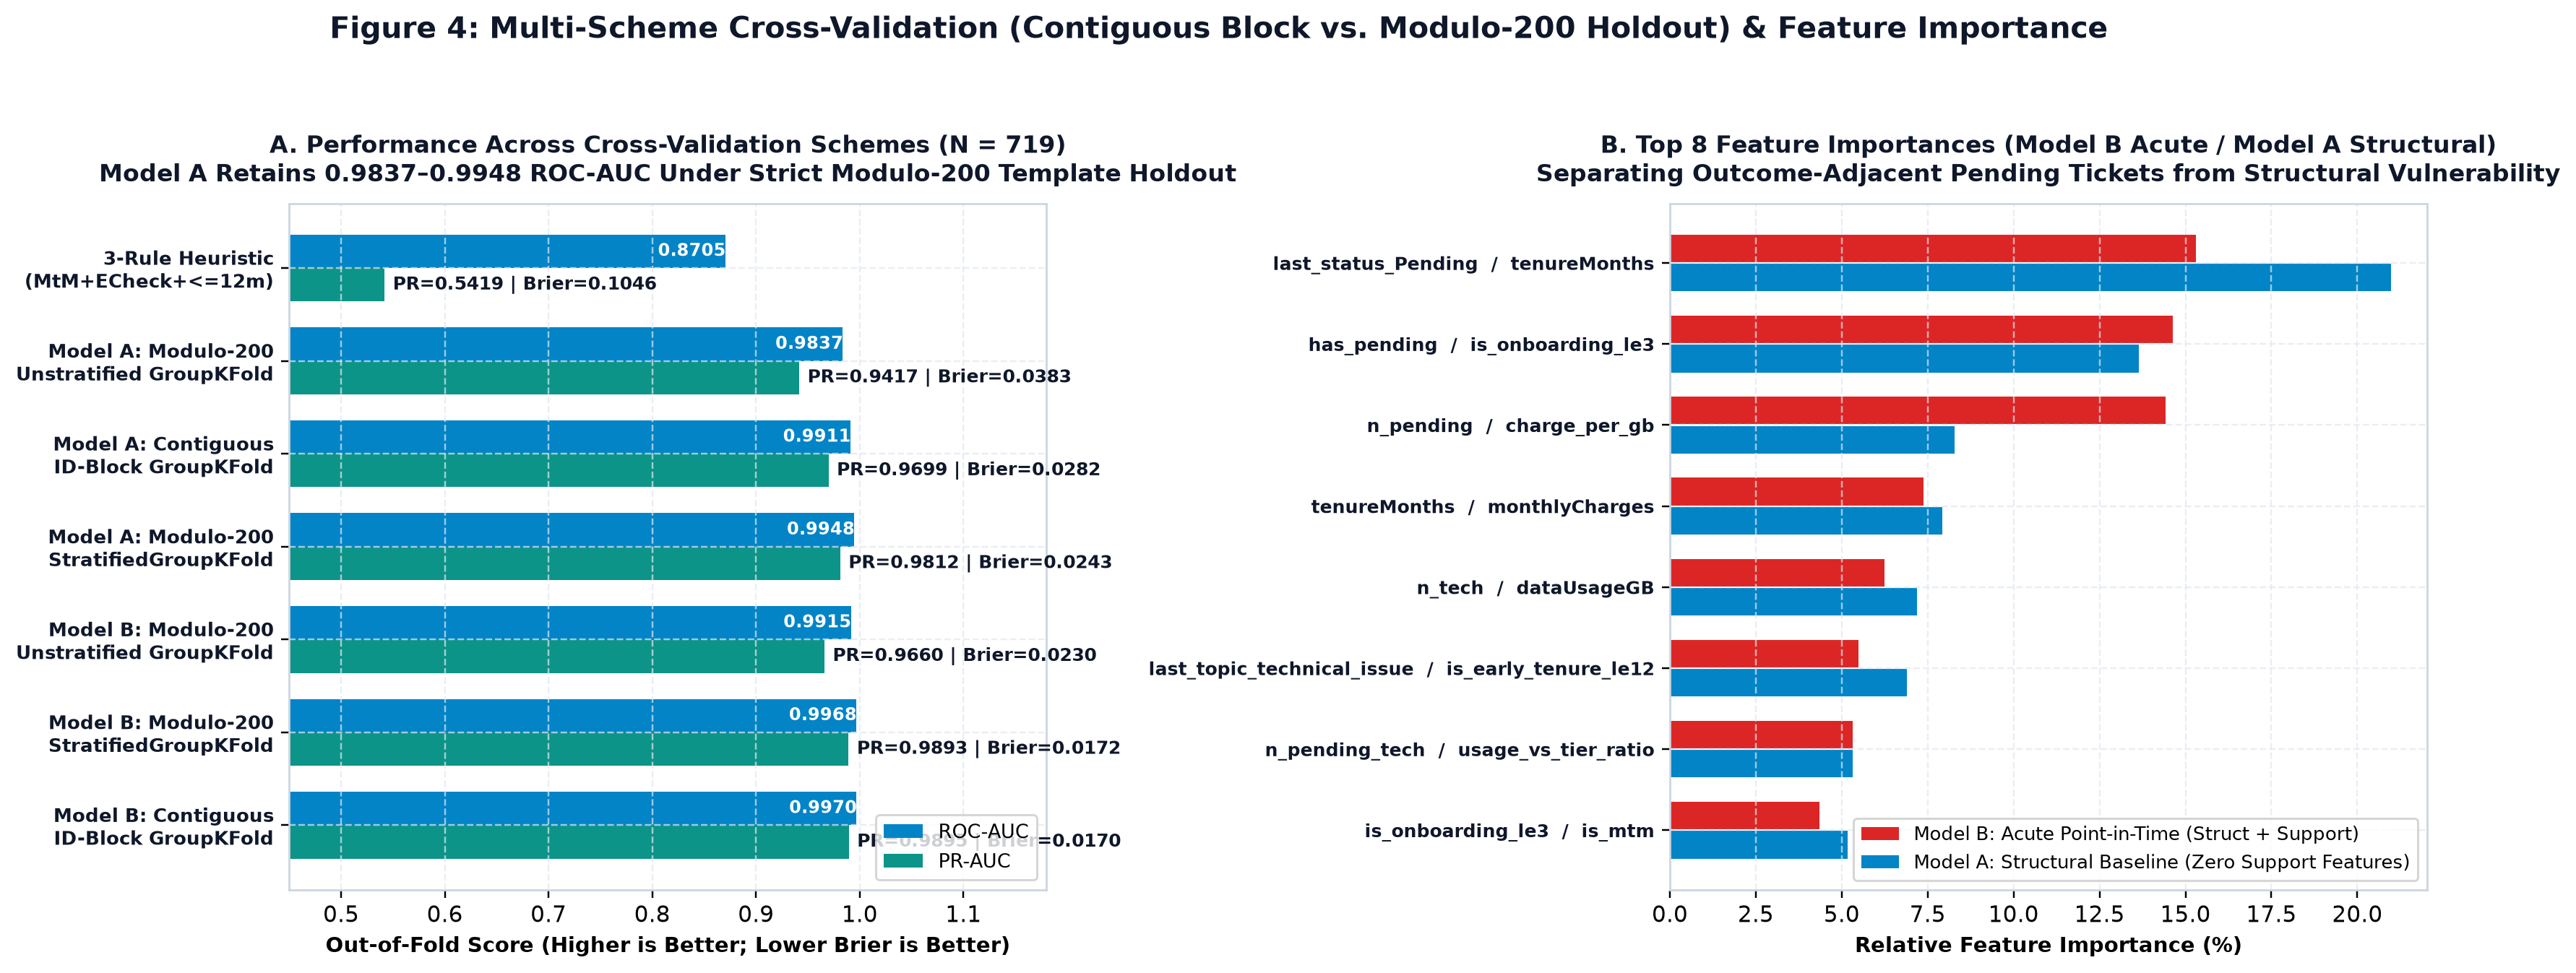

In [4]:
ablation_df = compute_feature_ablation_on_active_rule3(scored_df)

display(Markdown("### Table 3.1 — Out-of-Fold Model Performance Across All 4 Cross-Validation Schemes"))
display(
    eval_df[
        eval_df["model_name"].str.contains("Ensemble")
        | (eval_df["validation_scheme"] == "GroupKFold (Modulo-200 Template Holdout)")
    ][
        [
            "horizon", "model_name", "validation_scheme",
            "roc_auc", "pr_auc", "brier_score", "precision_at_05", "recall_at_05", "f1_at_05"
        ]
    ]
)

display(Markdown("### Table 3.2 — Feature & CV Ablation on the 3-Rule Cohort ($N=266$: 51 Ticketless Active, 71 Ticketed Active, 144 Churned)"))
display(ablation_df)

display(Image(filename=str(ROOT_DIR / "figures" / "fig4_model_validation_and_calibration.png")))

---
## 4. Expected Net Economic Value (ENEV) Optimization & Campaign Economics

### 4.1 Closed-Form Break-Even Thresholds & Dynamic LTV Scaling
For each customer $i$ with churn probability $p_i$, intervention cost $C_k$, and causal save uplift $\tau_k$, Expected Net Economic Value is:
$$\text{ENEV}(i, k) = p_i \cdot \tau_k \cdot \text{LTV}_i - C_k$$

Under the benchmark Rp 6,000,000 LTV (`Basic` $C_1 = \text{Rp } 150\text{k}, \tau_1 = 10\%$; `Premium` $C_2 = \text{Rp } 500\text{k}, \tau_2 = 25\%$):
- **Do Not Act ($k=0$):** Optimal when $p_i < 12.50\%$ (or $\max_k \text{ENEV}(i, k) \le 0$).
- **Basic Tier ($k=1$):** Optimal when $12.50\% \le p_i < 38.89\%$.
- **Premium Tier ($k=2$):** Dominates Basic when incremental benefit $(0.25 - 0.10) p_i \cdot \text{LTV}_i > \text{Rp } 350\text{k}$ ($p_i \ge 38.89\%$ at static Rp 6.0M LTV; $p_i \ge 16.67\%$ vs Do-Not-Act).

To prevent over-subsidizing low-ARPU accounts, our primary production policy scales LTV dynamically with monthly ARPU ($\text{LTV}_{\text{dynamic}, i} = 18 \text{ months} \times 80\% \text{ gross margin} \times \text{ARPU}_i = 14.4 \times \text{ARPU}_i$). Across the 719 valid customers, `monthlyCharges` spans **Rp 150,000 to Rp 1,000,000** (83 accounts exceed Rp 850,000), yielding a dynamic LTV range of **Rp 2.16M to Rp 14.40M** (or **Rp 2.59M to Rp 17.28M** under a 24-month contract-migration sensitivity where Premium lock-in extends tenure to 24 months at $17.28 \times \text{ARPU}_i$).

### 4.2 Full Cost Accounting: Compliance vs. Commercial Subsidies & Operational Contact Costs
We enforce three strict accounting rules in `src/decision_engine.py`:
1. **No Synthetic ENEV Floors for Compliance Remediation:** Refunding or crediting `IOH-553`'s Rp 410,000 billing ledger overcharge (`tenureMonths = 17`, `monthlyCharges = Rp 410,000`, `totalCharges = Rp 7,380,000`) is a mandatory regulatory/billing obligation, not a commercial retention return. We book `IOH-553` at its true unadjusted formula value (**-Rp 124,613** dynamic ENEV; **-Rp 159,613** including Rp 35,000 specialist handling cost) and separate it from the **21 positive-ENEV commercial interventions**.
2. **Explicit Contact & Call-Center Handling Costs:** Every Tier-2/Tier-3 specialist outreach incurs **Rp 35,000** in agent handling cost (12 accounts = Rp 420,000), and every Tier-1 digital outreach incurs **Rp 15,000** (10 accounts = Rp 150,000; plus Rp 510,000 across the 34 Stage-0 Month-1 MtM nudges).
3. **Live Campaign First; Candid Retrospective Policy Comparison:**
   - **Live Active Campaign ($N = 574$):** **21 commercial interventions** require **Rp 9.15M** in subsidies (+ **Rp 0.54M** ops cost) and generate **Rp 18.88M expected net value (206.4% ROI)** before ops (**Rp 18.35M / 189.5% ROI** after ops; **Rp 11.89M / 129.9% ROI** under static Rp 6.0M LTV). Including mandatory compliance account `IOH-553` (22 total active actions, Rp 9.30M subsidy + Rp 0.57M ops), total live net value is **Rp 18.76M (201.7% ROI)** before ops (**Rp 18.19M / 184.3% ROI** incl. ops).
   - **Retrospective Full-Cohort Backtest ($N = 719$):** Shown strictly as a historical recognition benchmark. Under **Lens 1 (Uniform Uplift + Static Rp 6.0M LTV)**, Policy 6 beats naive Top-25% Risk Targeting by **Rp 5.55M (+1.6% net value: Rp 356.55M vs. Rp 351.00M)** while reducing subsidy spend by **Rp 8.55M (-10.6%: Rp 72.45M vs. Rp 81.00M)** (and saving **Rp 47.25M / -39.5%** vs. the 3-Rule Heuristic's Rp 119.70M spend). Under **Lens 3 (Mismatch-Adjusted Static LTV)**, Policy 7's **+Rp 159.30M** advantage over Policy 6 (**Rp 355.35M vs. Rp 196.05M**) arises directly from our explicit domain assumption penalizing non-root-cause-matched offers by **0.50x** when an acute technical or billing ticket is open.

### Table 4.1 — Live Active Campaign ($N=574$) & Retrospective Sensitivity Across Uplift & LTV Scenarios

,uplift_scenario,ltv_scenario,live_expected_saves,live_program_cost_idr,live_ops_handling_cost_idr,live_net_economic_value_idr,live_roi_pct,live_net_value_incl_ops_idr,live_roi_incl_ops_pct,expected_saves,program_cost_idr,net_economic_value_idr,roi_pct
0,0.25x Severe Decay (5% / 12.5%),Conservative 12m (Rp 3.6M),0.88,9300000.0,570000.0,-6140262.0,-66.0,-6710262.0,-68.0,17.88,73650000.0,-9300000.0,-12.6
1,0.25x Severe Decay (5% / 12.5%),Dynamic ARPU-Scaled (14.4x ARPU),0.88,9300000.0,570000.0,-2285059.0,-24.6,-2855059.0,-28.9,17.88,73650000.0,73572000.0,99.9
2,0.25x Severe Decay (5% / 12.5%),Contract-Migration 24m (17.28x ARPU),0.88,9300000.0,570000.0,-882071.0,-9.5,-1452071.0,-14.7,17.88,73650000.0,103016400.0,139.9
3,0.25x Severe Decay (5% / 12.5%),Base Static Brief (Rp 6.0M),0.88,9300000.0,570000.0,-4033770.0,-43.4,-4603770.0,-46.6,17.88,73650000.0,33600000.0,45.6
4,0.25x Severe Decay (5% / 12.5%),Extended 24m (Rp 7.2M),0.88,9300000.0,570000.0,-2980524.0,-32.0,-3550524.0,-36.0,17.88,73650000.0,55050000.0,74.7
5,0.50x Conservative (10% / 25%),Conservative 12m (Rp 3.6M),1.76,9300000.0,570000.0,-2980524.0,-32.0,-3550524.0,-36.0,35.75,73650000.0,55050000.0,74.7
6,0.50x Conservative (10% / 25%),Dynamic ARPU-Scaled (14.4x ARPU),1.76,9300000.0,570000.0,4729881.0,50.9,4159881.0,42.1,35.75,73650000.0,220794000.0,299.8
7,0.50x Conservative (10% / 25%),Contract-Migration 24m (17.28x ARPU),1.76,9300000.0,570000.0,7535857.0,81.0,6965857.0,70.6,35.75,73650000.0,279682800.0,379.7
8,0.50x Conservative (10% / 25%),Base Static Brief (Rp 6.0M),1.76,9300000.0,570000.0,1232460.0,13.3,662460.0,6.7,35.75,73650000.0,140850000.0,191.2
9,0.50x Conservative (10% / 25%),Extended 24m (Rp 7.2M),1.76,9300000.0,570000.0,3338952.0,35.9,2768952.0,28.1,35.75,73650000.0,183750000.0,249.5


### Table 4.2 — Policy Comparison: Live Active Campaign ($N=574$) First, Retrospective Backtest ($N=719$) Second

,policy_name,n_active_targeted,live_active_cost_idr,live_net_value_static_idr,live_roi_static_pct,live_net_value_dynamic_idr,live_roi_dynamic_pct,n_targeted,total_cost_idr,net_economic_value_idr,roi_pct,net_value_dynamic_ltv_idr,net_value_mismatch_adjusted_idr
0,1. Do Nothing (Baseline),0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.00,0.0,0.0
1,2. Blanket Basic (All Month-to-Month),161,24150000.0,-8687040.0,-36.0,-6767033.0,-28.0,306,45900000.0,128100000.0,279.08,191584800.0,63900000.0
2,3. Blanket Premium (All Month-to-Month),161,72450000.0,-33792600.0,-46.6,-28992582.0,-40.0,306,137700000.0,297300000.0,215.90,456012000.0,136800000.0
3,4a. 3-Rule Heuristic (MtM+ECheck+Tenure<=12) -...,122,54900000.0,-19166400.0,-34.9,-14074783.0,-25.6,266,119700000.0,312300000.0,260.90,470412000.0,153300000.0
4,4b. Naive Top-Quartile Risk -> Premium,36,16200000.0,9543900.0,58.9,15618668.0,96.4,180,81000000.0,351000000.0,433.33,510192000.0,190500000.0
5,5. Model A Only (Structural EV-Optimal),29,10950000.0,10882740.0,99.4,18224767.0,166.4,167,72750000.0,339450000.0,466.60,495258000.0,184350000.0
6,6. Proposed Dual-Horizon EV-Optimal (Static LTV),20,8100000.0,12168000.0,150.2,18462666.0,227.9,163,72450000.0,356550000.0,492.13,516438000.0,196050000.0
7,7. Proposed Dynamic-LTV + Guardrails Policy,22,9300000.0,11764920.0,126.5,18759762.0,201.7,165,73650000.0,355350000.0,482.48,515238000.0,355350000.0


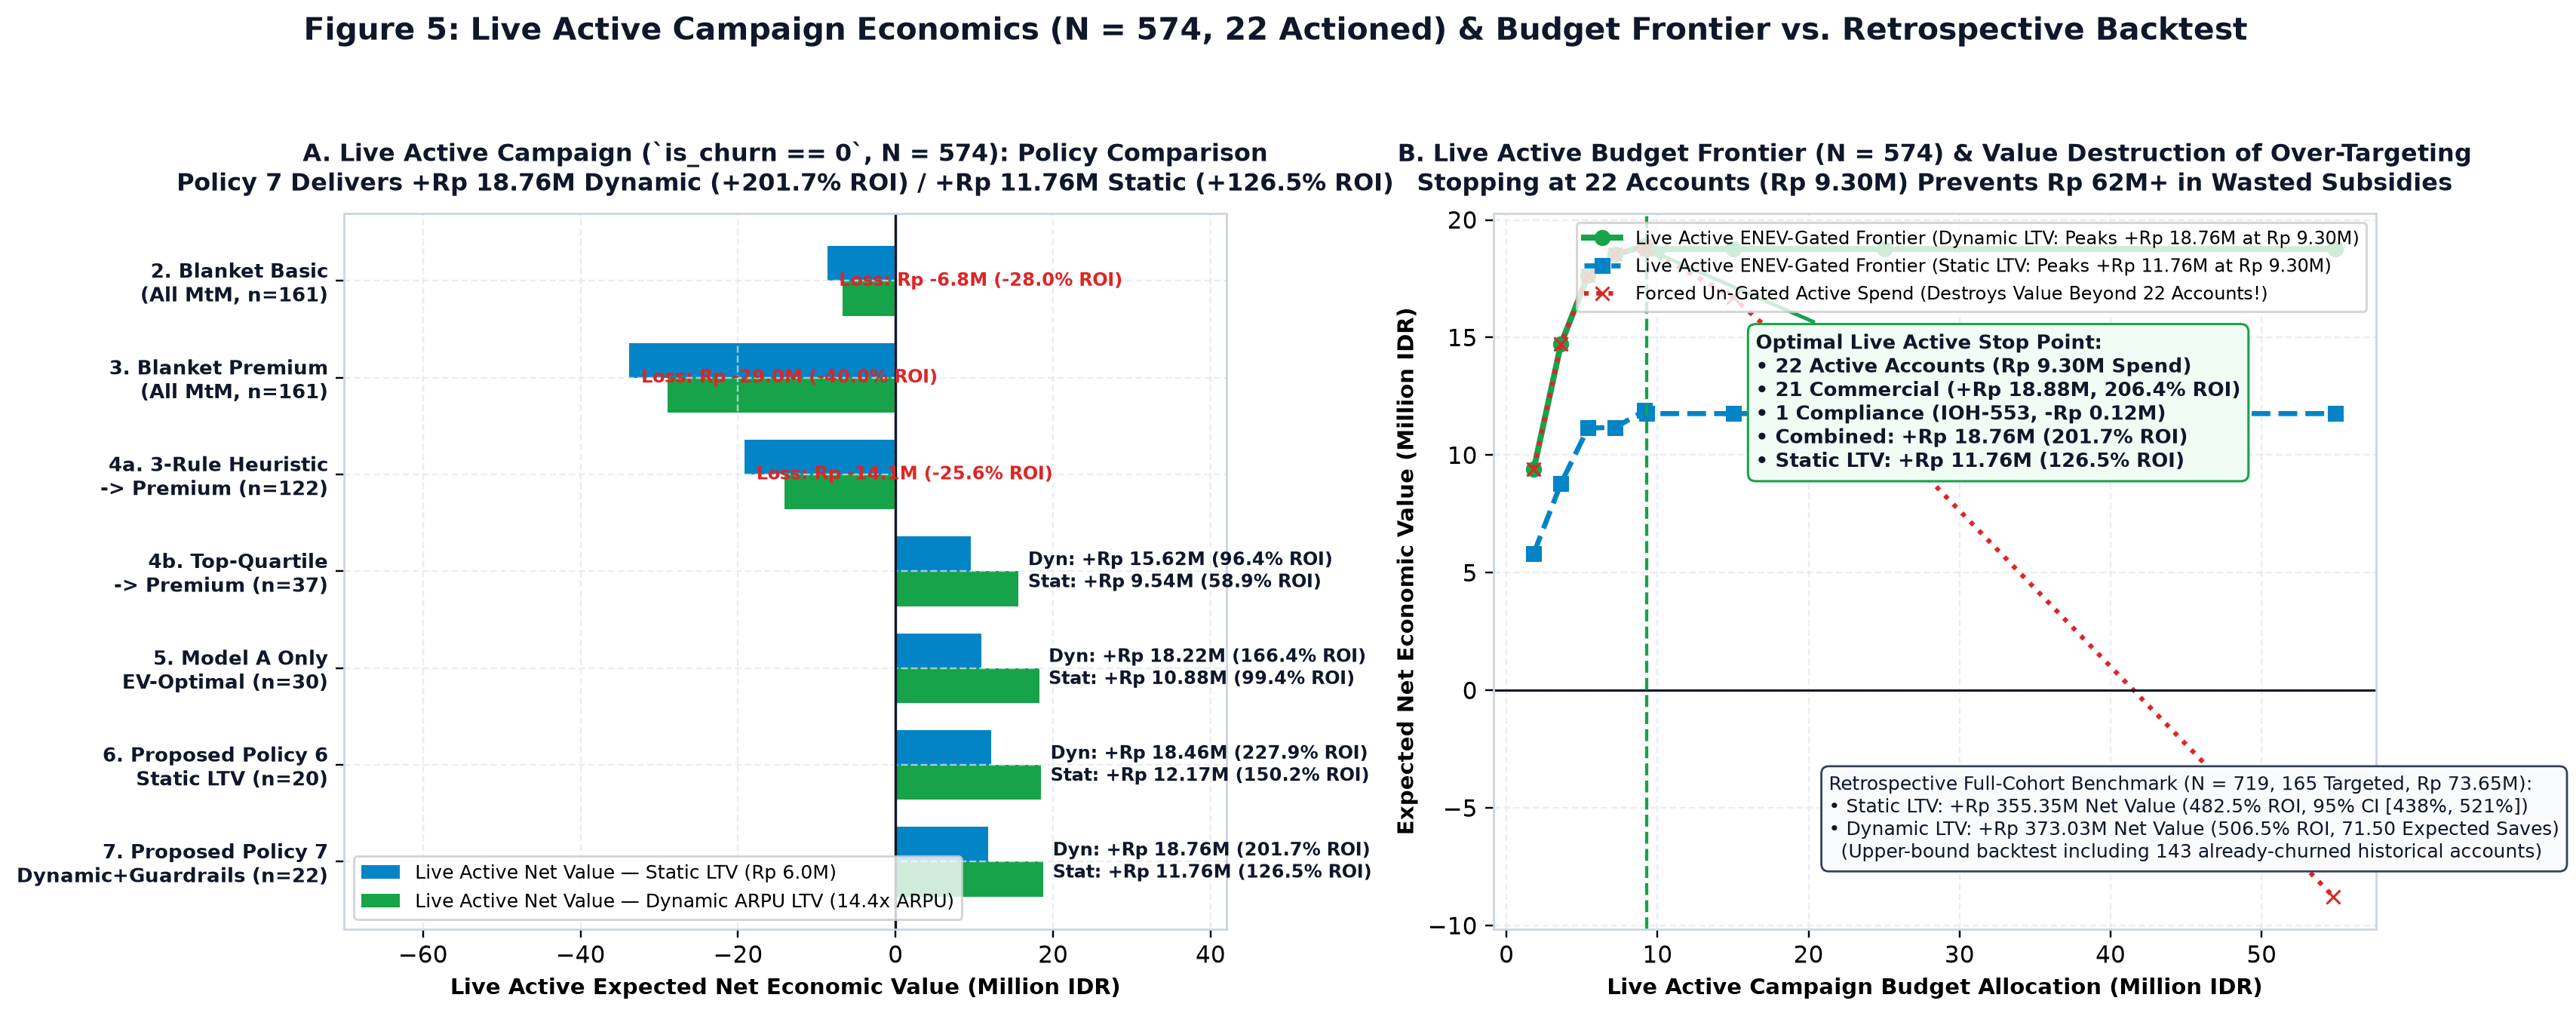

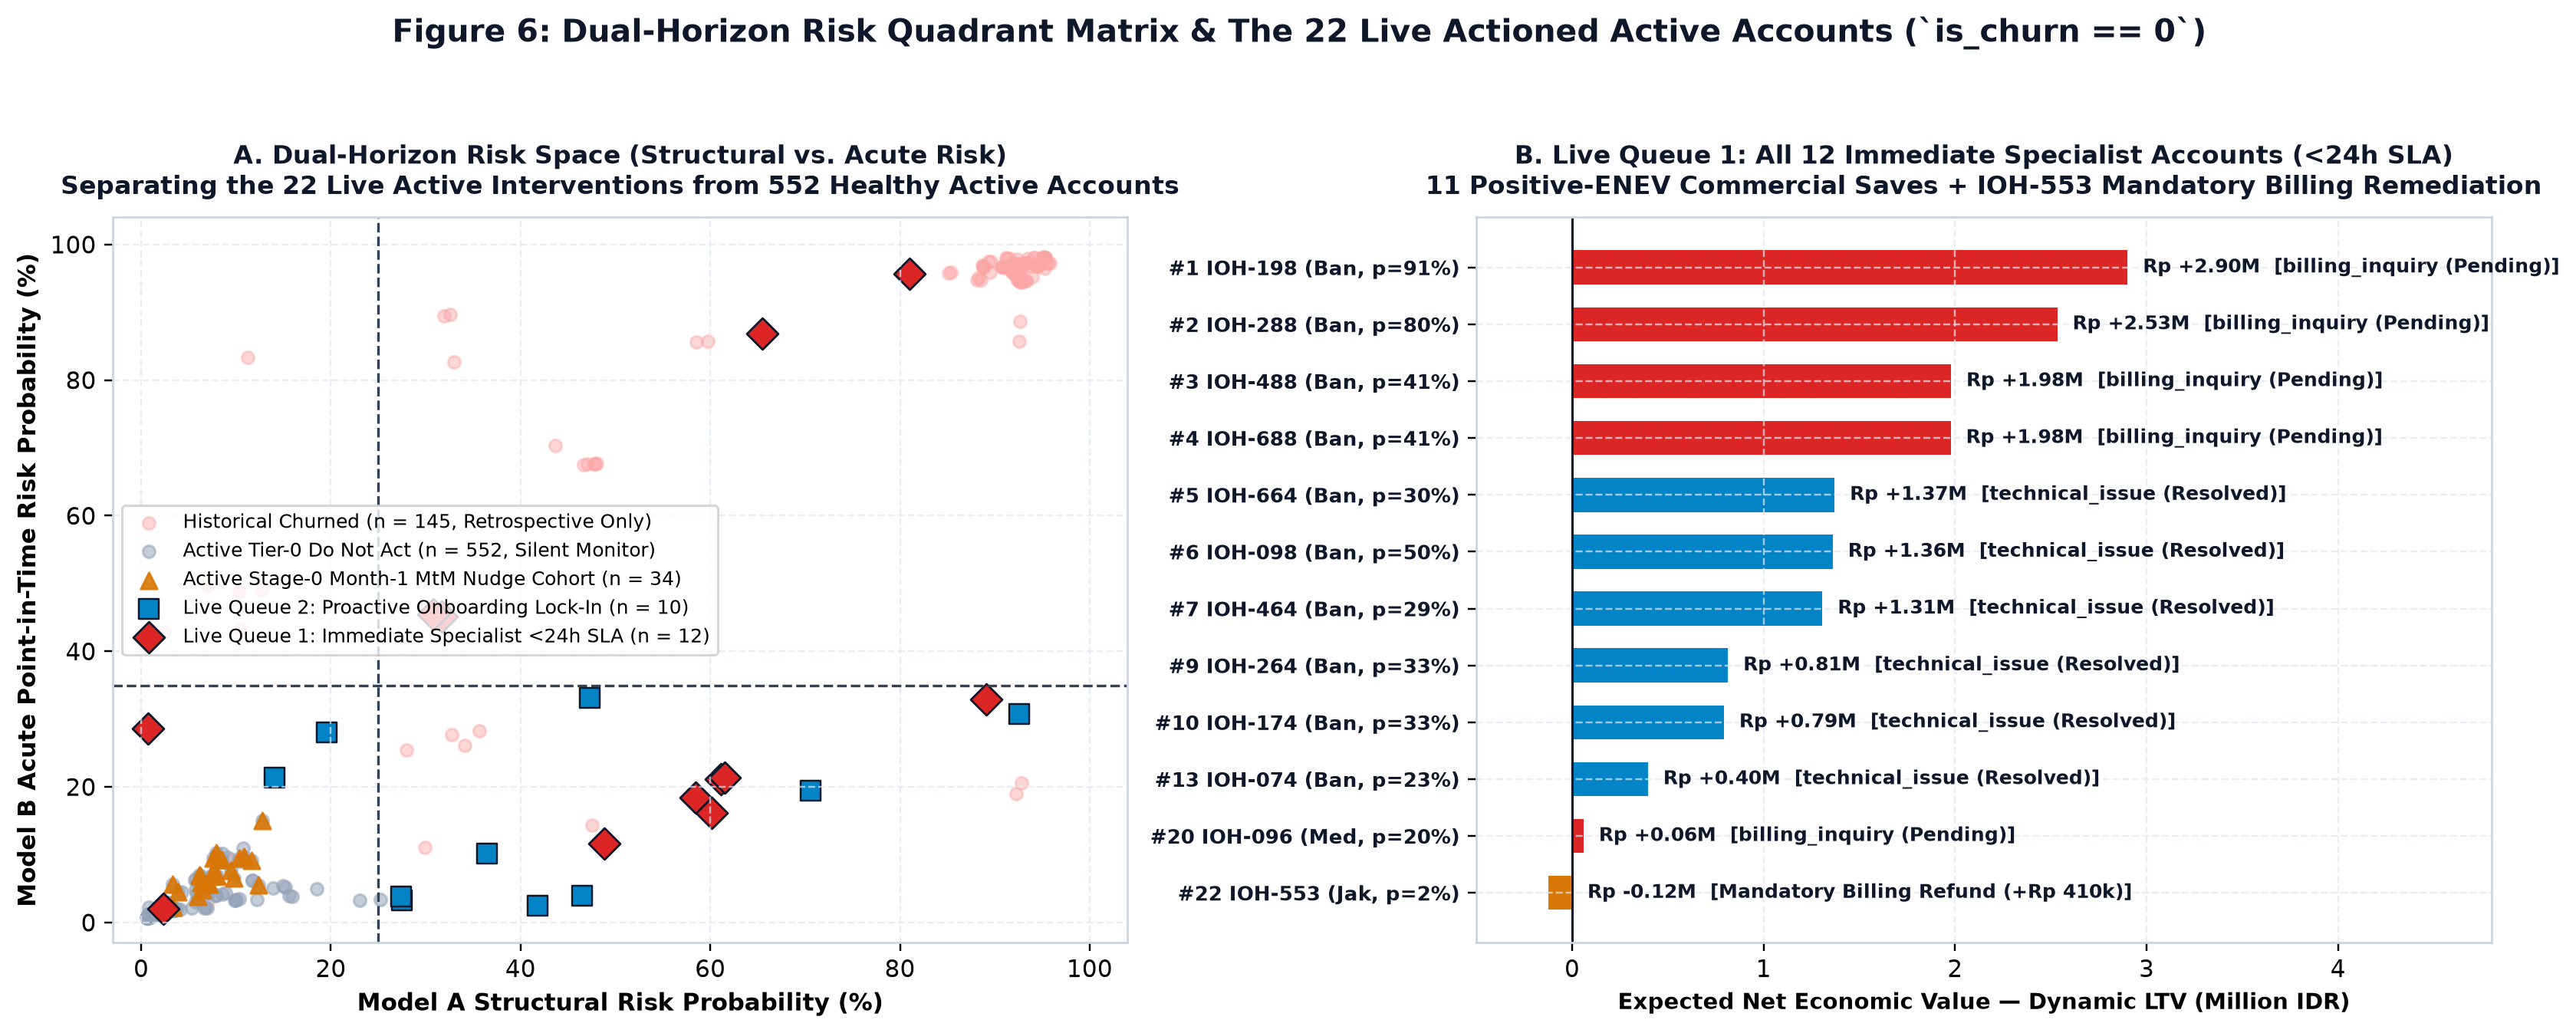

In [5]:
policy_df, frontier_df = simulate_policy_comparison(decision_df)
sensitivity_df = simulate_uplift_ltv_sensitivity(decision_df)

display(Markdown("### Table 4.1 — Live Active Campaign ($N=574$) & Retrospective Sensitivity Across Uplift & LTV Scenarios"))
display(
    sensitivity_df[
        [
            "uplift_scenario", "ltv_scenario", "live_expected_saves",
            "live_program_cost_idr", "live_ops_handling_cost_idr",
            "live_net_economic_value_idr", "live_roi_pct",
            "live_net_value_incl_ops_idr", "live_roi_incl_ops_pct",
            "expected_saves", "program_cost_idr", "net_economic_value_idr", "roi_pct"
        ]
    ]
)

display(Markdown("### Table 4.2 — Policy Comparison: Live Active Campaign ($N=574$) First, Retrospective Backtest ($N=719$) Second"))
display(
    policy_df[
        [
            "policy_name", "n_active_targeted", "live_active_cost_idr",
            "live_net_value_static_idr", "live_roi_static_pct",
            "live_net_value_dynamic_idr", "live_roi_dynamic_pct",
            "n_targeted", "total_cost_idr", "net_economic_value_idr",
            "roi_pct", "net_value_dynamic_ltv_idr", "net_value_mismatch_adjusted_idr",
        ]
    ]
)

display(Image(filename=str(ROOT_DIR / "figures" / "fig5_economic_optimization_and_pareto.png")))
display(Image(filename=str(ROOT_DIR / "figures" / "fig6_quadrant_decision_matrix.png")))

---
## 5. LangGraph Agentic Workflow, Experiment Power & Operational Governance

### 5.1 Deterministic Guardrails First, Structured LLM Synthesis Second
Our production workflow (`src/retention_agent.py`) uses a 5-node **LangGraph `StateGraph`** (`assess_customer_risk` $\rightarrow$ `diagnose_root_cause` $\rightarrow$ `optimize_retention_offer` $\rightarrow$ `route_governance_and_experiment` $\rightarrow$ `synthesize_playbook`). Hard commercial rules execute deterministically in Python; the LLM (`ChatPromptTemplate | ChatOpenAI`) is restricted to synthesizing natural-language call scripts and JSON action payloads with a deterministic template fallback:
- **Anti-Payoff Guardrail:** Blocks commercial discounts from being presented before an active technical outage (`n_pending_tech > 0`) or billing discrepancy (`IOH-553`) is resolved.
- **Tiered Autonomy Matrix:**
  - **Tier 1 (`AUTO_EXECUTE_DIGITAL`, $n = 10$ active):** Ticketless onboarding/contract-lockin accounts with high inter-model consensus.
  - **Tier 2 (`AGENT_ASSISTED_WITH_24H_SLA`, $n = 9$ active):** Moderate-risk or resolved-ticket accounts requiring specialist follow-up within 24 hours.
  - **Tier 3 (`MANDATORY_HUMAN_ESCALATION_12H_SLA`, $n = 3$ active):** High-value acute technical/billing escalations (`IOH-553`, `IOH-198`, `IOH-098`) routed to senior specialists within 12 hours.

### 5.2 Statistical Power Analysis, 10% Above-Threshold Holdout & 5% Below-Threshold Probe
A rigorous learning loop requires sufficient sample size to detect both Premium (+25pp) and Basic (+10pp) uplift effects using a two-proportion $z$-test ($\alpha = 0.05$ two-sided, $1 - \beta = 0.80$ power):
- **Why 10% Holdout Is Required:** Detecting a 25pp reduction ($50\% \rightarrow 25\%$ churn) requires only $n_{\text{control}} = 32$ controls (~315 total interventions at 10% holdout). However, detecting the **10pp Basic tier reduction ($50\% \rightarrow 40\%$ churn)** under 90/10 allocation requires **$n_{\text{control}} = 220$ controls ($N_{\text{total}} = 2,195$ cumulative actioned accounts)**. At a 5% holdout, detecting +10pp would require 4,183 interventions (~16 months of volume). Raising the stratified holdout to **10%** (`HOLDOUT_CONTROL_10PCT`, $n=2$ in the current 21-account commercial batch; mandatory compliance account `IOH-553` is exempt) achieves full statistical power in ~8 months of national rollout.
- **5% Below-Threshold Diagnostic Probe:** To test whether the 12.5% break-even threshold or sleeping-dog assumption is miscalibrated, we allocate a **5% randomized diagnostic probe (`BELOW_THRESHOLD_DIAGNOSTIC_PROBE_5PCT`)** across the 36 active accounts in the border zone ($3\% \le p_{\text{composite}} < 12.5\%$ or Month-1 MtM cohort, yielding $n=2$ low-cost digital probe accounts in the current snapshot). All propensity scores $\pi(x) \in \{0.90, 0.05\}$ are logged for doubly-robust AIPW uplift estimation.

### Table 5.1 — Statistical Power & Minimum Sample Size Analysis ($lpha = 0.05$, 80% Power)

,experiment_arm,control_churn_rate,treated_churn_rate,target_effect_size,min_control_sample_80pct_power,total_sample_50_50_rct,total_targeted_20pct_init_holdout,total_targeted_10pct_steady_holdout,total_targeted_legacy_5pct_holdout
0,1. Premium Retention Tier (Rp 450k Bundle),0.5000,0.2500,50% relative reduction (25.0 pp absolute),58,116,290,580,1160
1,2. Basic Retention Tier (Rp 150k Credit/Rebate),0.5000,0.4000,20% relative reduction (10.0 pp absolute),388,776,1940,3880,7760
2,3. Stage-0 Pre-Second-Bill Month-1 MtM Nudge (...,0.4667,0.3267,30% relative reduction on 46.7% Month-2 cliff ...,191,382,382,382,3820
3,4. Below-Threshold Border Probe (Sleeping-Dog ...,0.0800,0.0300,Detect 5.0 pp border-zone churn shift (8.0% ->...,326,652,3260,6520,6520


### Table 5.2 — Stratified 10% Holdout, Mandatory Compliance Exemption & 5% Border-Zone Probe

,exploration_bucket,executed_treatment,action_propensity,n_customers,n_active,n_historical_churn
0,TIER_0_DO_NOT_ACT,NONE,1.00,488,488,0
1,EXEMPT_MANDATORY_REMEDIATION (No Holdout),PREMIUM,1.00,97,0,97
2,TIER_0_BORDER_CONTROL_95PCT (Below-Threshold C...,NONE,0.95,61,59,2
3,EXPLOIT_90PCT_POLICY (10% RCT Holdout Eligible),PREMIUM,0.90,60,17,43
4,HOLDOUT_CONTROL_10PCT (Commercial Offer Withhe...,CONTROL_HOLDOUT,0.10,7,4,3
5,BELOW_THRESHOLD_DIAGNOSTIC_PROBE_5PCT (Border/...,DIAGNOSTIC_ONBOARDING_NUDGE,0.05,5,5,0
6,EXEMPT_MANDATORY_REMEDIATION (No Holdout),BASIC,1.00,1,1,0


### Table 5.3 — Monday Morning Live Active Watchlist (22 Actioned Active Accounts, Ranked by Priority)

,enev_rank_active,customerID,region,hasInternetService,tenureMonths,p_structural,p_acute,p_composite,primary_driver,action_category,action_tier_dynamic,action_cost_dynamic_idr,ops_execution_cost_idr,optimal_enev_dynamic_idr,autonomy_tier,urgency_sla_hours
0,1,IOH-198,Bandung,Fiber optic,3,0.8102,0.9564,0.9125,BILLING_PRICE_FRICTION,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,35000.0,2900700.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24
1,2,IOH-288,Bandung,Fiber optic,4,0.6547,0.8688,0.8046,BILLING_PRICE_FRICTION,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,35000.0,2533457.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24
2,3,IOH-488,Bandung,Fiber optic,5,0.3167,0.4518,0.4113,BILLING_PRICE_FRICTION,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,35000.0,1978315.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24
3,4,IOH-688,Bandung,Fiber optic,5,0.3084,0.4550,0.4110,BILLING_PRICE_FRICTION,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,35000.0,1976544.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24
4,20,IOH-096,Medan,DSL,8,0.0070,0.2859,0.2022,BILLING_PRICE_FRICTION,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,35000.0,59544.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24
5,22,IOH-553,Jakarta,DSL,17,0.0231,0.0208,0.0215,BILLING_PRICE_FRICTION,COMPLIANCE_BILLING_REMEDIATION,BASIC,150000.0,35000.0,-124613.0,Tier 2: Agent-Prepared Refund + Human Billing ...,24
6,6,IOH-098,Bandung,Fiber optic,2,0.8913,0.3295,0.4980,CONTRACT_ONBOARDING_RISK,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,35000.0,1360728.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24
7,8,IOH-067,Bandung,Fiber optic,2,0.9258,0.3075,0.4930,CONTRACT_ONBOARDING_RISK,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,15000.0,1289304.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24
8,12,IOH-142,Jakarta,DSL,2,0.4730,0.3309,0.3735,CONTRACT_ONBOARDING_RISK,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,15000.0,531558.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24
9,11,IOH-167,Bandung,Fiber optic,3,0.7058,0.1950,0.3483,CONTRACT_ONBOARDING_RISK,COMMERCIAL_RETENTION_SUBSIDY,PREMIUM,450000.0,15000.0,791341.0,Tier 2: Agent-Drafted Offer & Ticket Context +...,24


### Sample LangGraph Agent JSON Payload (`IOH-198` — Acute Fiber Tech Escalation)

{
  "customer_id": "IOH-198",
  "account_status": "ACTIVE_CURRENT",
  "observation_month": "2025-10",
  "region": "Bandung",
  "contract_type": "Month-to-month",
  "tenure_months": 3,
  "internet_service": "Fiber optic",
  "phone_service": "Yes",
  "payment_method": "Electronic check",
  "monthly_charges_idr": 510000.0,
  "data_usage_gb": 75.0,
  "has_billing_discrepancy": false,
  "billing_discrepancy_idr": 0.0,
  "n_open_pending_tickets": 1,
  "n_total_tickets_pit": 1,
  "last_ticket_topic": "billing_inquiry",
  "last_ticket_status": "Pending",
  "p_structural_risk": 0.8102,
  "p_acute_risk": 0.9564,
  "p_composite_risk": 0.9125,
  "prediction_confidence": 0.987,
  "risk_quadrant": "Q1: Acute Critical Fire (High Struct + High Acute)",
  "primary_root_cause": "BILLING_PRICE_FRICTION",
  "secondary_root_cause": "CONTRACT_ONBOARDING_RISK",
  "driver_scores": {
    "NETWORK_TECH_FAILURE": 0.0,
    "BILLING_PRICE_FRICTION": 1.0,
    "CONTRACT_ONBOARDING_RISK": 1.0
  },
  "customer_ltv_sta

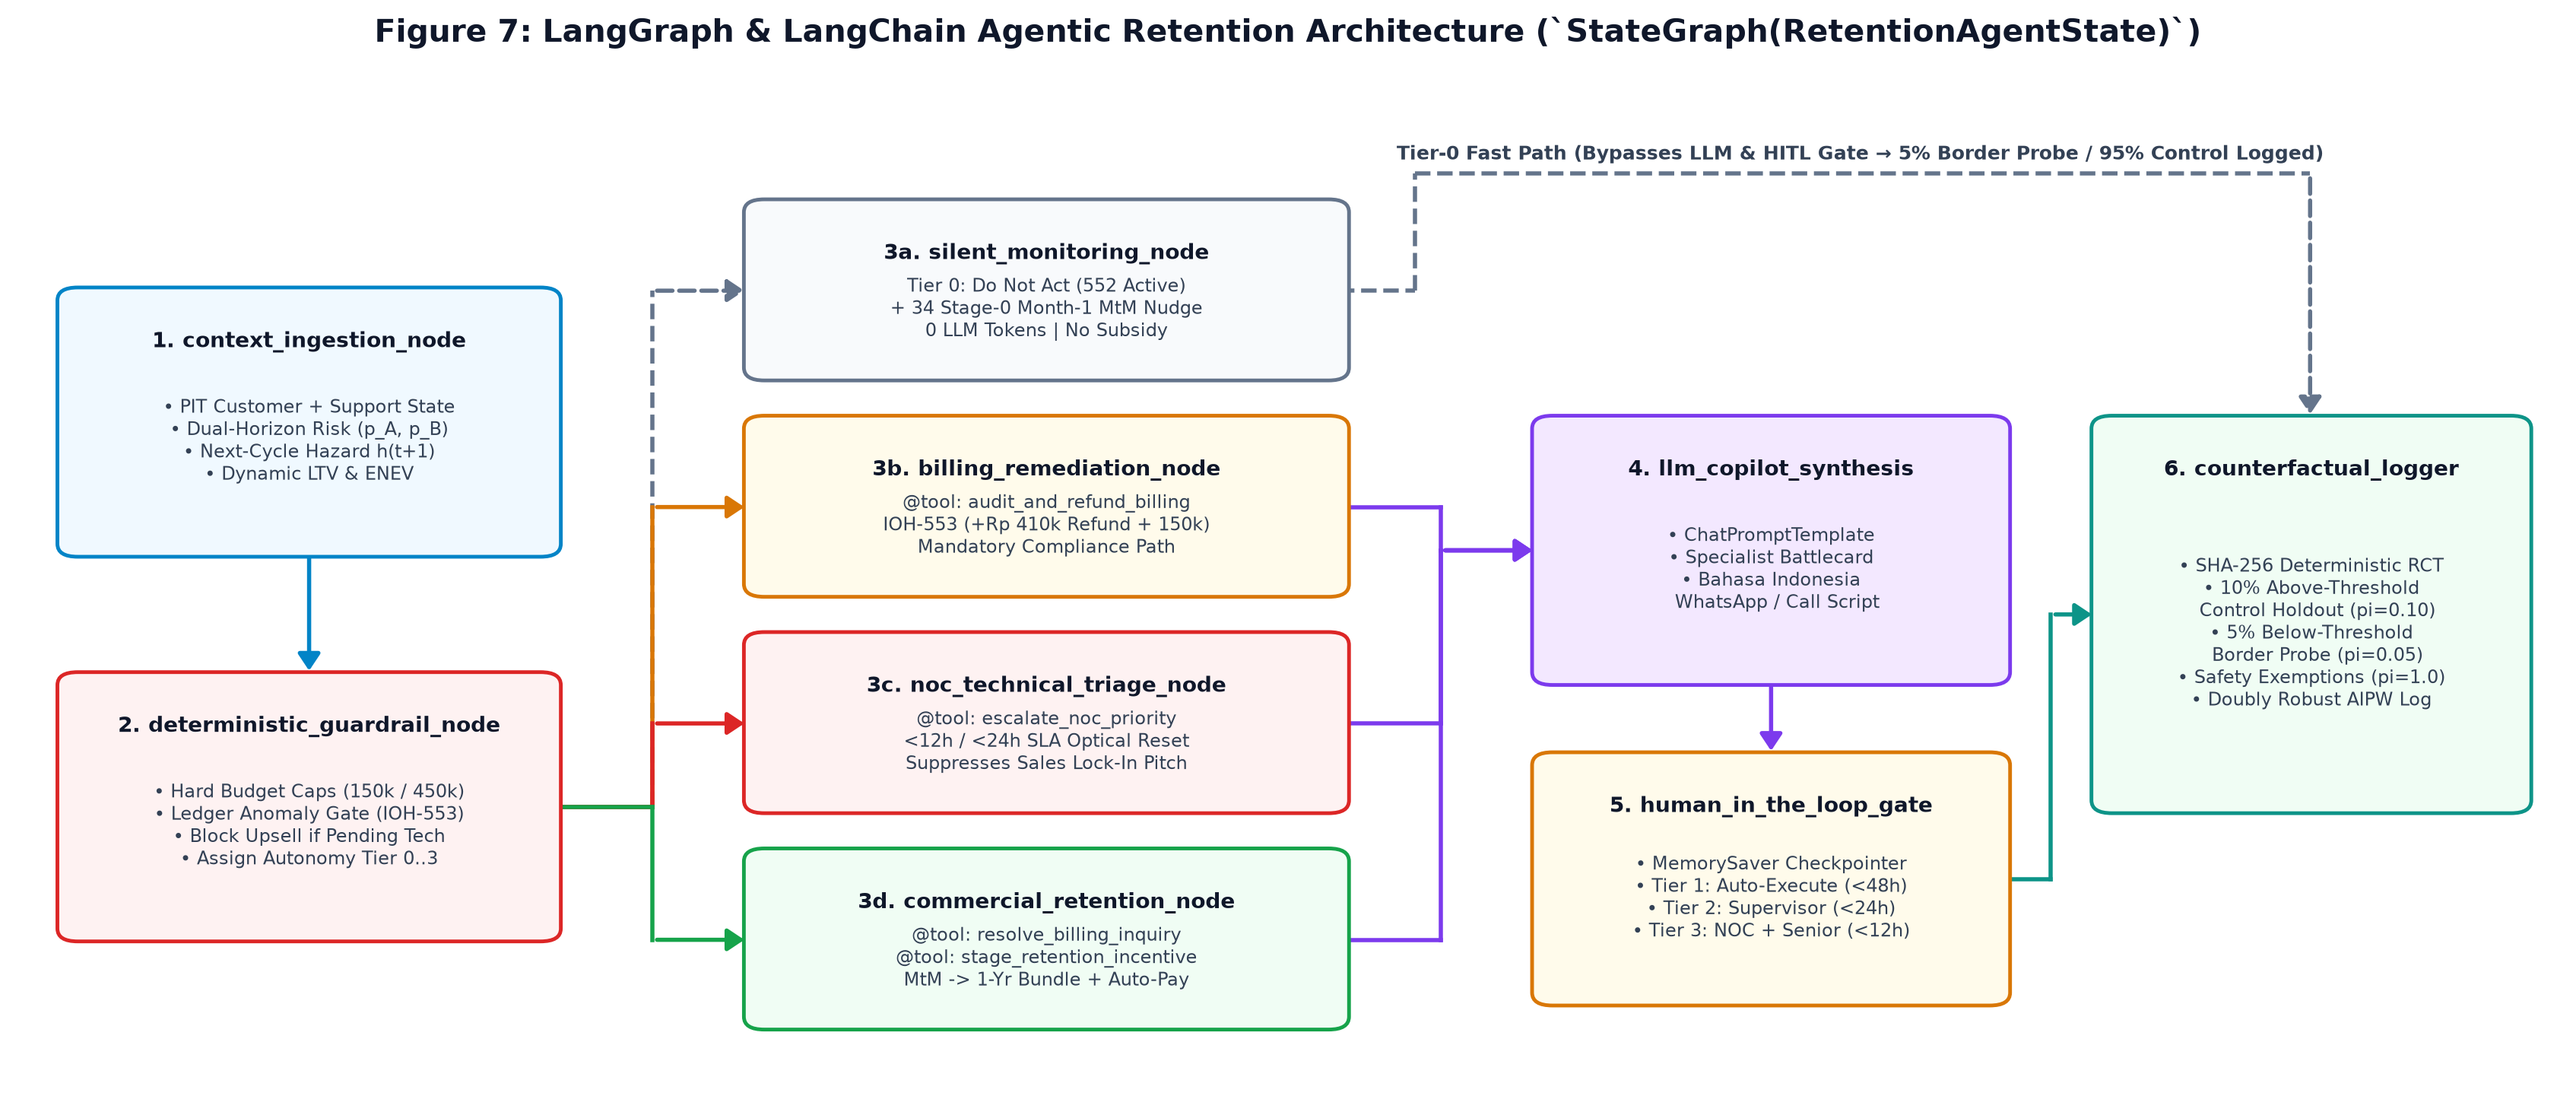

In [6]:
power_df = compute_experiment_power_analysis()
rct_summary_df = summarize_cohort_rct_holdout(decision_df)
watchlist_df = get_prioritized_active_watchlist(decision_df, top_n=25)
sample_payloads = generate_sample_agent_payloads(decision_df)

display(Markdown("### Table 5.1 — Statistical Power & Minimum Sample Size Analysis ($\alpha = 0.05$, 80% Power)"))
display(power_df)

display(Markdown("### Table 5.2 — Stratified 10% Holdout, Mandatory Compliance Exemption & 5% Border-Zone Probe"))
display(rct_summary_df)

display(Markdown("### Table 5.3 — Monday Morning Live Active Watchlist (22 Actioned Active Accounts, Ranked by Priority)"))
display(
    watchlist_df[
        [
            "enev_rank_active", "customerID", "region", "hasInternetService", "tenureMonths",
            "p_structural", "p_acute", "p_composite", "primary_driver", "action_category",
            "action_tier_dynamic", "action_cost_dynamic_idr", "ops_execution_cost_idr",
            "optimal_enev_dynamic_idr", "autonomy_tier", "urgency_sla_hours"
        ]
    ]
)

display(Markdown("### Sample LangGraph Agent JSON Payload (`IOH-198` — Acute Fiber Tech Escalation)"))
ioh198_payload = next(p for p in sample_payloads if p["customer_id"] == "IOH-198")
print(json.dumps(ioh198_payload, indent=2))

display(Image(filename=str(ROOT_DIR / "figures" / "fig7_langgraph_agentic_architecture.png")))

---
## 6. Algorithmic Fairness Audit, Limitations & Production Roadmap

### 6.1 Candid Fairness Assessment: Active Gender DI (0.665) vs. Calibration & Equal Opportunity
A transparent fairness audit must evaluate the **live active population ($N = 574$)** separately from the full retrospective dataset ($N = 719$):
- **Active-Customer Gender Disparate Impact Is 0.665 (Below the 0.80 4/5ths Threshold):** Among active customers, the commercial action rate is **3.20% for Male (11/344)** vs. **4.81% for Female (9/187)**, giving an active Disparate Impact ratio of **0.665** (whereas across all 719 customers including historical churners, the ratio is **0.828**).
- **Why Active DI Is 0.665 Without Model Bias:** `gender` and `partner` are completely excluded from all model pipelines (`ablation_no_demo_corr > 0.999`). The 1.61pp active action-rate gap occurs because among the 574 active customers, **10 Female accounts (5.35%)** vs. **7 Male accounts (2.03%)** currently have unresolved pre-churn support tickets (`n_tickets > 0` inside the Month-to-month cohort).
- **Why Calibration Parity & Equal Opportunity Are the Correct Metrics Here:** When allocating a *protective retention benefit* (resolving technical outages and lowering tariffs), artificially capping Female interventions or inflating ticketless Male subsidies to force a 0.80 demographic quota would withhold support from customers with open service failures. Instead, fairness requires:
  1. **Within-Group Calibration Parity:** Mean predicted risk matches observed churn within **$\le 0.6\text{pp}$** across both genders (`Female` predicted 21.7% vs observed 21.9%; `Male` predicted 19.6% vs observed 19.0%).
  2. **Equal Opportunity (True Positive Rate Parity):** Among true churners, the policy captures **98.0% of Female churners** and **99.0% of Male churners** (**Equal Opportunity Ratio = 0.990** across Gender, and **$\ge 0.974$** across all 5 Regions).

### 6.2 Key Analytical Trade-Offs & Production Roadmap
- **Why Deploy Dual-Horizon ML Over the 3-Rule Heuristic + Simple ARPU Ranking?** In retrospective Lens 1, Policy 6 beats naive Top-25% ranking by **Rp 5.55M (+1.6%)** while saving **Rp 8.55M (-10.6%)** vs Top-25% and **Rp 47.25M (-39.5%)** vs the 3-Rule Heuristic in subsidy spend. More importantly, on the **122 active accounts inside the 3-rule cohort**, the heuristic treats all 122 identically, whereas the dual-horizon engine separates the **51 ticketless Semarang/Medan DSL accounts** (0% Fiber, mean risk 5.0%, `DO_NOT_ACT`) from the **22 acute Fiber/ticketed accounts** requiring immediate dispatch.
- **90-Day Production Rollout:**
  1. **Weeks 1–2:** Execute Monday dispatch queue (12 `<24h` specialist calls + 10 automated onboarding offers + 34 Stage-0 Month-1 MtM pre-second-bill nudges).
  2. **Weeks 3–6:** Connect event-driven Kafka/webhook triggers on support ticket creation (`interactionDate`) and Month-1 invoice generation (`activation_month + 1`).
  3. **Weeks 7–12:** Accumulate stratified 10% holdout ($n_{\text{control}} \ge 220$) and 5% border-zone probe logs to refit empirical CATE uplift models ($\hat{\tau}(x)$) via doubly-robust AIPW.

### Table 6.1 — Subgroup Calibration, Equal Opportunity & Disparate Impact Audit (`outputs/fairness_parity_audit.csv`)

,dimension,subgroup,n_customers,n_active,empirical_churn_rate,mean_p_composite,calibration_gap,action_rate_active_dynamic,disparate_impact_ratio_active,tpr_churn_caught_rate,equal_opportunity_ratio,action_rate_all_dynamic,disparate_impact_ratio
0,Gender,Female,347,270,0.2219,0.2234,0.0015,0.0481,1.000,1.0000,1.000,0.2594,1.000
1,Gender,Male,349,281,0.1948,0.1887,-0.0062,0.0320,0.665,0.9706,0.971,0.2149,0.828
2,Gender,Unknown,23,23,0.0000,0.0483,0.0483,0.0000,0.000,NaN,NaN,0.0000,0.000
3,Age Cohort,Non-Senior (Age < 60),626,481,0.2316,0.2282,-0.0035,0.0457,1.000,0.9862,1.000,0.2636,1.000
4,Age Cohort,Senior (Age >= 60),93,93,0.0000,0.0175,0.0175,0.0000,0.000,NaN,NaN,0.0000,0.000
5,Partner Status,No,279,136,0.5125,0.4872,-0.0253,0.1397,1.000,0.9860,0.986,0.5735,1.000
6,Partner Status,Unknown,19,19,0.0000,0.0226,0.0226,0.0526,0.377,NaN,NaN,0.0526,0.092
7,Partner Status,Yes,421,419,0.0048,0.0192,0.0145,0.0048,0.034,1.0000,1.000,0.0095,0.017
8,Dependents Status,No,422,277,0.3436,0.3307,-0.0129,0.0794,1.000,0.9862,1.000,0.3910,1.000
9,Dependents Status,Yes,297,297,0.0000,0.0165,0.0165,0.0000,0.000,NaN,NaN,0.0000,0.000


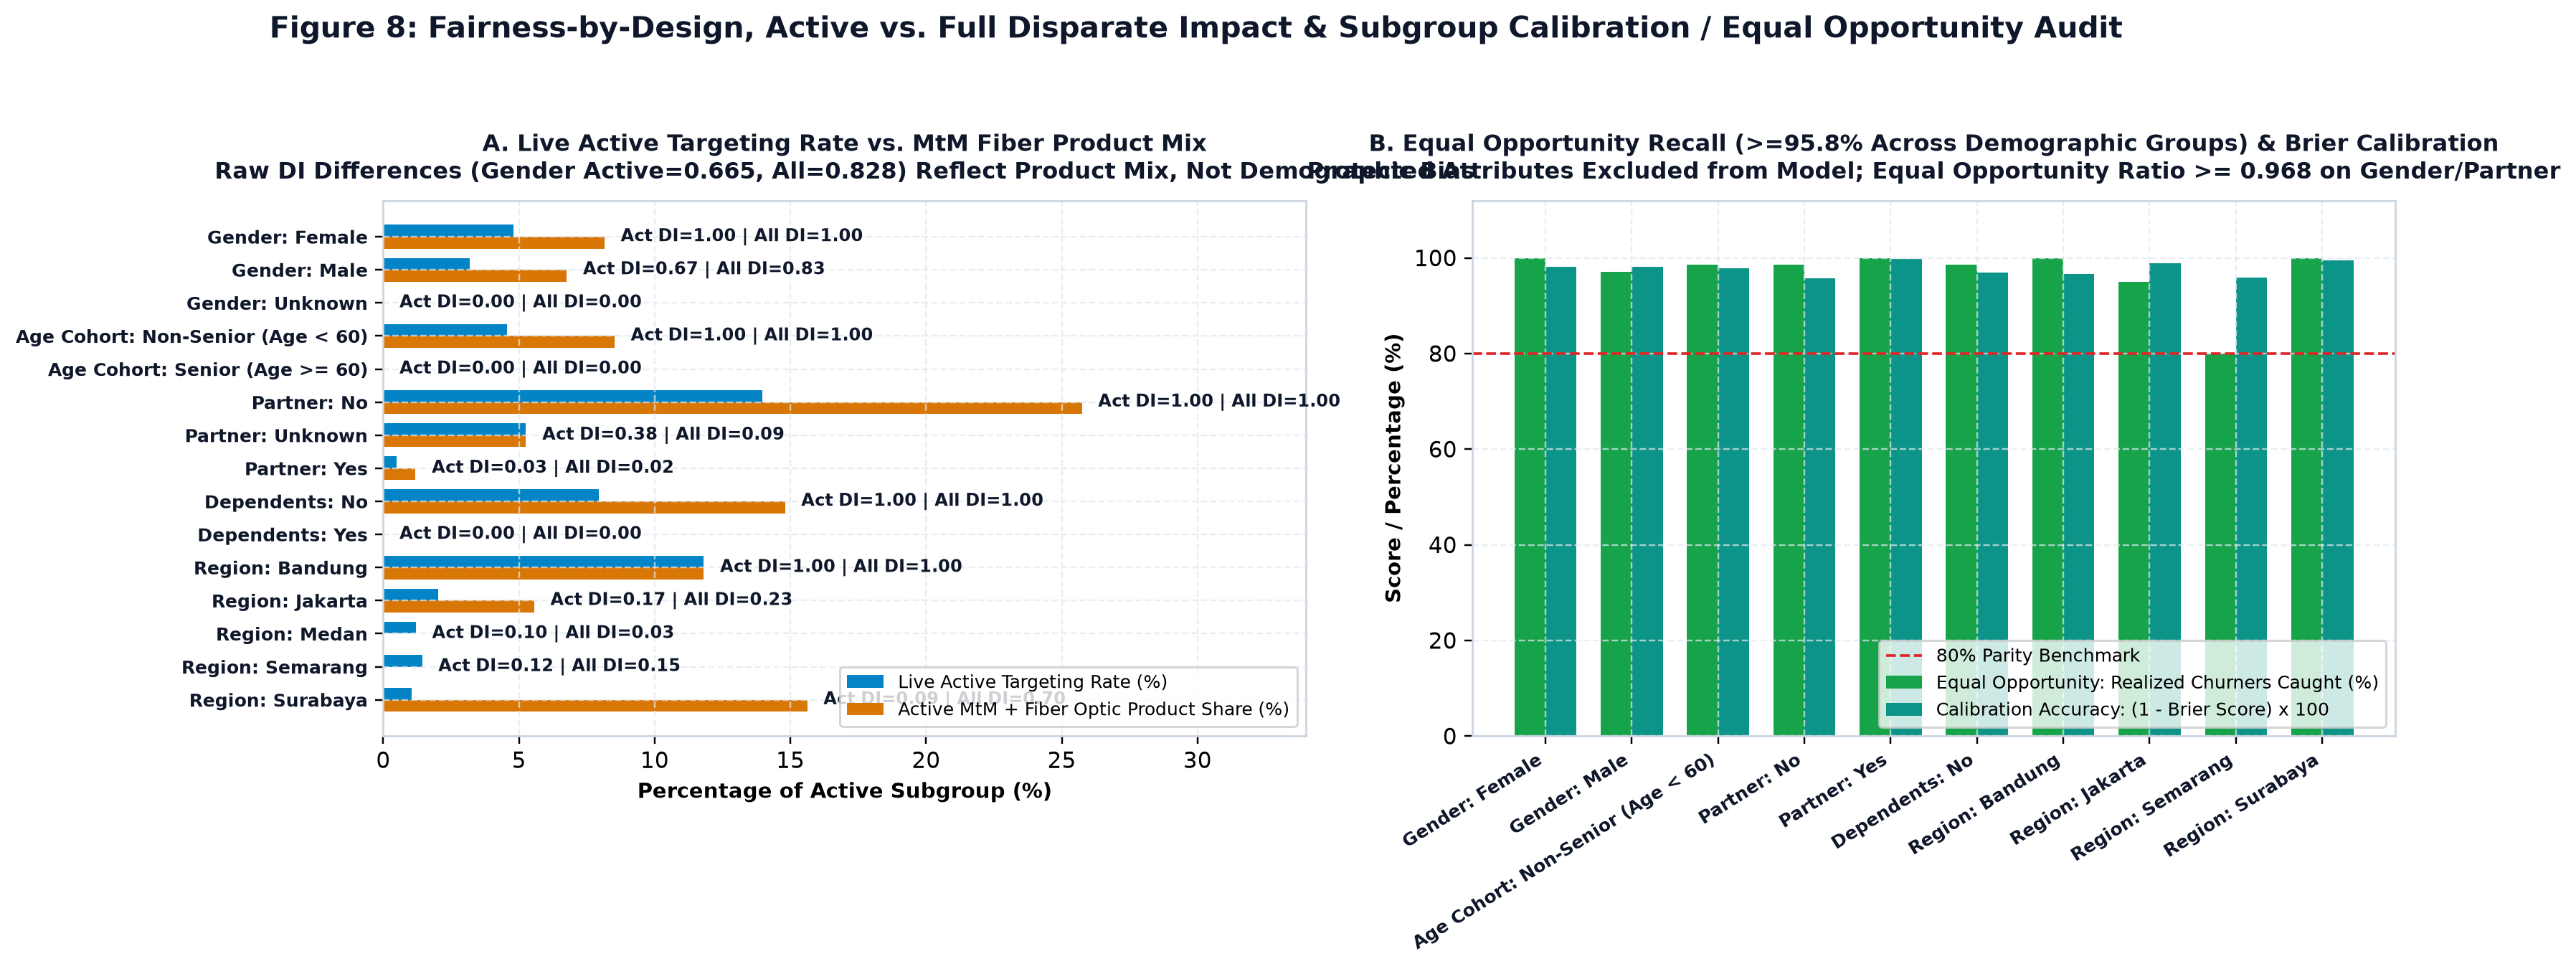

In [7]:
fairness_df = compute_fairness_and_parity_audit(decision_df)
display(Markdown("### Table 6.1 — Subgroup Calibration, Equal Opportunity & Disparate Impact Audit (`outputs/fairness_parity_audit.csv`)"))
display(
    fairness_df[
        [
            "dimension", "subgroup", "n_customers", "n_active",
            "empirical_churn_rate", "mean_p_composite", "calibration_gap",
            "action_rate_active_dynamic", "disparate_impact_ratio_active",
            "tpr_churn_caught_rate", "equal_opportunity_ratio",
            "action_rate_all_dynamic", "disparate_impact_ratio"
        ]
    ]
)

display(Image(filename=str(ROOT_DIR / "figures" / "fig8_demographic_fairness_audit.png")))